# 🔍 Named Entity Recognition with DeBERTa-v3 — Revised Edition (v2)
# 🔍 التعرف على الكيانات المسماة باستخدام DeBERTa-v3 — النسخة المعدلة (v2)

---

### 🎯 Project Summary / ملخص المشروع
- **EN:** Fine-tune `microsoft/deberta-v3-base` for token classification on **CoNLL-2003 (English)** with four entity types (`PER`, `ORG`, `LOC`, `MISC`), evaluate at entity level with `seqeval`, and deploy a Gradio app on Hugging Face Spaces.
- **AR:** تدريب نموذج `microsoft/deberta-v3-base` لمهمة تصنيف التوكنز على بيانات **CoNLL-2003 (إنجليزي)** بأربعة أنواع كيانات (`PER`, `ORG`, `LOC`, `MISC`)، مع تقييم على مستوى الكيان بـ `seqeval`، ثم نشر تطبيق Gradio على Hugging Face Spaces.

### 🛠️ What Changed vs. v1 / ما الذي تغير عن النسخة الأولى
1. **Official validation split / ملف التحقق الرسمي:** `valid.txt` is now used for model selection; the hidden `train_test_split` hack is removed. | تم استخدام `valid.txt` الرسمي وحذف تقسيم التدريب الخفي.
2. **`-DOCSTART-` removed / حذف علامات بداية المستند:** document markers are not real sentences. | العلامات ليست جمل حقيقية.
3. **Real validation / تحقق حقيقي:** the old token-vs-tag assert was always true; it now checks columns, BIO format and label coverage. | الـ assert القديم كان دائماً صحيحاً.
4. **Truncation audit / فحص القص:** guarantees no sentence is silently truncated. | لا جملة تُقص بصمت.
5. **Better training recipe / وصفة تدريب أفضل:** `lr=2e-5`, warmup + linear decay, weight decay, gradient clipping, fixed seed. | معدل تعلم أقل مع scheduler وclipping.
6. **Automatic best checkpoint + early stopping / اختيار أفضل نقطة تلقائياً:** no manual `copytree`. | بدون نسخ يدوي.
7. **Case-robustness / متانة الحروف:** lowercase augmentation in training + a lowercase test evaluation. | تعزيز بالحروف الصغيرة وتقييم مستقل.
8. **Space fixes / إصلاحات التطبيق:** CoNLL-style punctuation tokenization, single-source `app.py`, pinned requirements, `README.md`. | تقطيع بأسلوب CoNLL ومصدر واحد للتطبيق.
9. **Clean structure / بنية نظيفة:** consistent phases, no duplicated cells, no debug cells. | مراحل مرتبة بدون تكرار.

# Phase 0: Environment & Configuration
# المرحلة الصفرية: البيئة والإعدادات

---

### 🎯 Objective / الهدف
- **EN:** Install missing libraries, import everything once, centralize every hyper-parameter and path in one cell, and fix the random seed for reproducibility.
- **AR:** تثبيت المكتبات الناقصة، واستيراد كل شيء مرة واحدة، وتجميع كل الإعدادات والمسارات في خلية واحدة، وتثبيت البذرة العشوائية لتكرار النتائج.

In [1]:
!pip install -q seqeval sentencepiece  # تثبيت مكتبة التقييم ومكتبة التقطيع | Install evaluation and tokenizer libraries

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os  # أوامر النظام والمجلدات | OS and directory utilities
import re  # التعبيرات النمطية | Regular expressions
import json  # التعامل مع ملفات JSON | JSON handling
import shutil  # نسخ الملفات والمجلدات | File and folder copying
import zipfile  # فك الملفات المضغوطة | ZIP extraction
import importlib.metadata as importlib_metadata  # قراءة إصدارات المكتبات | Read installed library versions
from collections import Counter  # عدّاد التكرارات | Frequency counter

import numpy as np  # الحسابات الرقمية | Numerical computing
import pandas as pd  # الجداول المنسقة | Formatted tables
import torch  # مكتبة بايتورتش | PyTorch library
import matplotlib.pyplot as plt  # مكتبة الرسم الأساسية | Core plotting library
import seaborn as sns  # رسوم إحصائية متقدمة | Advanced statistical plots
from tqdm.auto import tqdm  # شريط التقدم | Progress bar
from google.colab import drive  # ربط جوجل درايف | Mount Google Drive

from torch.optim import AdamW  # المحسّن | Optimizer
from torch.utils.data import Dataset, DataLoader  # أدوات تحميل البيانات | Data loading utilities
from transformers import (  # استيراد أدوات Hugging Face | Import Hugging Face tools
    AutoTokenizer,  # المقطّع اللغوي | Tokenizer
    AutoModelForTokenClassification,  # نموذج تصنيف التوكنز | Token classification model
    AutoConfig,  # إعدادات النموذج | Model configuration
    DataCollatorForTokenClassification,  # حشو ديناميكي للدفعات | Dynamic batch padding
    get_linear_schedule_with_warmup,  # جدولة معدل التعلم | Learning-rate scheduler
    set_seed,  # تثبيت العشوائية | Seed everything
)  # نهاية الاستيراد | End of import
from seqeval.metrics import (  # مقاييس مستوى الكيان | Entity-level metrics
    classification_report,  # تقرير مفصل لكل نوع | Per-type report
    f1_score,  # مقياس F1 | F1 score
    precision_score,  # الدقة | Precision
    recall_score,  # الاستدعاء | Recall
    accuracy_score,  # دقة التوكنز | Token accuracy
)  # نهاية الاستيراد | End of import
from seqeval.metrics.sequence_labeling import get_entities  # استخراج حدود الكيانات | Extract entity spans
from sklearn.metrics import confusion_matrix  # مصفوفة الإرباك | Confusion matrix

In [3]:
# ----------------------- Reproducibility | قابلية التكرار -----------------------
SEED = 42  # البذرة العشوائية الثابتة | Fixed random seed
set_seed(SEED)  # تثبيت عشوائية بايثون ونمباي وبايتورتش | Seed Python, NumPy and PyTorch

# ----------------------- Model & data | النموذج والبيانات -----------------------
MODEL_NAME = "microsoft/deberta-v3-base"  # النموذج المدرب مسبقاً | Pretrained backbone
MAX_LENGTH = 256  # أقصى طول للتوكنز الفرعية | Max sub-word sequence length

# ----------------------- Training hyper-parameters | إعدادات التدريب -----------------------
BATCH_SIZE = 16  # حجم دفعة التدريب | Training batch size
EVAL_BATCH_SIZE = 32  # حجم دفعة التقييم | Evaluation batch size
LEARNING_RATE = 2e-5  # معدل التعلم (قيمة DeBERTa-v3 القياسية) | Learning rate (standard DeBERTa-v3 value)
WEIGHT_DECAY = 0.01  # تنظيم الأوزان | Weight decay
WARMUP_RATIO = 0.1  # نسبة الإحماء من إجمالي الخطوات | Warmup fraction of total steps
NUM_EPOCHS = 5  # أقصى عدد إيبوكات | Maximum number of epochs
PATIENCE = 2  # صبر الإيقاف المبكر | Early-stopping patience
MAX_GRAD_NORM = 1.0  # حد قص الجراديانت | Gradient clipping threshold
MAX_SKIPPED_STEPS = 20  # أقصى عدد خطوات غير سليمة قبل إيقاف التدريب | Max non-finite steps before aborting
LOWER_PROB = 0.2  # احتمال تحويل جملة التدريب لحروف صغيرة | Chance of lowercasing a training sentence

# ----------------------- Paths | المسارات -----------------------
ZIP_PATH = "/content/drive/MyDrive/NER_.zip"  # ملف البيانات المضغوط | Zipped dataset path
EXTRACT_PATH = "/content/dataset"  # مكان فك الضغط | Extraction folder
SCHEMA_PATH = "/content/drive/MyDrive/label_schema.json"  # مخطط الوسوم على الدرايف | Label schema on Drive
DRIVE_MODEL_DIR = "/content/drive/MyDrive/ner_best_model"  # نسخة احتياطية لأفضل نموذج | Best-model backup on Drive
CHECKPOINT_DIR = "./checkpoints"  # مجلد نقاط الحفظ | Checkpoints folder
BEST_DIR = "./checkpoints/best_model"  # مجلد أفضل نموذج | Best-model folder
BUNDLE_DIR = "./space_bundle"  # مجلد حزمة النشر الكاملة | Full Space bundle folder
DEPLOYMENT_DIR = "./space_bundle/deployment_artifacts"  # ملفات النموذج للنشر | Model artifacts for deployment
REPO_ID = "MohamedBelal-AI/ner-entity-recognition"  # اسم الـ Space | Space repository id

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # تحديد جهاز التدريب | Select training device
print(f"✅ Config ready | device = {device} | model = {MODEL_NAME} | seed = {SEED}")  # تأكيد الإعدادات | Confirm configuration

✅ Config ready | device = cuda | model = microsoft/deberta-v3-base | seed = 42


# Phase 1: Data Engineering & Label Schema Lock
# المرحلة الأولى: هندسة البيانات وتثبيت مخطط التصنيفات

---

### 🎯 Objective / الهدف
1. **Load & Validate / التحميل والتحقق:**
   - **EN:** Parse the CoNLL files, validate columns and BIO format, and remove `-DOCSTART-` document markers (they are not real sentences).
   - **AR:** قراءة ملفات CoNLL والتحقق من الأعمدة وصيغة BIO، وحذف علامات `-DOCSTART-` لأنها ليست جمل حقيقية.
2. **Label Schema Lock / قفل مخطط التصنيفات:**
   - **EN:** Build `label2id` / `id2label` from the training set only, assert that validation and test labels are covered, and persist the schema as JSON.
   - **AR:** بناء القواميس من بيانات التدريب فقط، والتأكد من أن وسوم التحقق والاختبار مغطاة، وحفظ المخطط في ملف JSON.

In [4]:
drive.mount("/content/drive")  # ربط الدرايف للوصول للملفات | Mount Drive to access files

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:  # فتح الملف المضغوط | Open the ZIP archive
    zip_ref.extractall(EXTRACT_PATH)  # فك الضغط فعلياً | Extract all files


def find_file(root, filename):  # دالة البحث عن ملف داخل المجلد وما تحته | Locate a file anywhere under a folder
    for dirpath, _, files in os.walk(root):  # المرور على المجلدات الفرعية | Walk through sub-folders
        if filename in files:  # لو الملف موجود هنا | If the file is here
            return os.path.join(dirpath, filename)  # إرجاع المسار الكامل | Return the full path
    raise FileNotFoundError(f"{filename} not found under {root}")  # خطأ واضح لو مش موجود | Clear error when missing


TRAIN_PATH = find_file(EXTRACT_PATH, "train.txt")  # مسار ملف التدريب | Train file path
VALID_PATH = find_file(EXTRACT_PATH, "valid.txt")  # مسار ملف التحقق الرسمي | Official validation file path
TEST_PATH = find_file(EXTRACT_PATH, "test.txt")  # مسار ملف الاختبار | Test file path
print("📂 Files found:", TRAIN_PATH, VALID_PATH, TEST_PATH, sep="\n   ")  # عرض المسارات | Print the paths

Mounted at /content/drive
📂 Files found:
   /content/dataset/train.txt
   /content/dataset/valid.txt
   /content/dataset/test.txt


# Step 1: Define CoNLL Loader, BIO Audit & DOCSTART Filter
# الخطوة 1: تعريف دوال القراءة وفحص صيغة BIO وحذف DOCSTART

---

### 🎯 Objective / الهدف
- **EN:** Define `load_conll_data` (raises on malformed lines), `audit_bio` (counts format violations and orphan `I-` tags) and `drop_docstart`. The v1 assert compared two lists built together, so it could never fail; the new checks can.
- **AR:** تعريف `load_conll_data` (ترفع خطأ عند السطور التالفة) و`audit_bio` (تعد مخالفات الصيغة ووسوم `I-` اليتيمة) و`drop_docstart`. الـ assert القديم كان يقارن قائمتين تُبنيان معاً فلا يفشل أبداً، أما الفحوصات الجديدة فيمكن أن تفشل فعلاً.

In [5]:
def load_conll_data(file_path):  # دالة قراءة ملف CoNLL مع تحقق حقيقي | Read a CoNLL file with real validation
    sentences = []  # قائمة الجمل النهائية | Final list of sentences
    tokens = []  # مخزن توكنز الجملة الحالية | Buffer for current tokens
    tags = []  # مخزن وسوم الجملة الحالية | Buffer for current tags

    with open(file_path, "r", encoding="utf-8") as f:  # فتح الملف بترميز UTF-8 | Open file with UTF-8
        lines = f.readlines()  # قراءة كل السطور | Read all lines

    for line_num, raw_line in enumerate(lines, 1):  # المرور على السطور مع أرقامها | Iterate lines with numbers
        line = raw_line.strip()  # إزالة المسافات الزائدة | Strip whitespace
        if not line:  # سطر فارغ = نهاية جملة | Blank line = sentence boundary
            if tokens:  # لو فيه جملة متجمعة | If a sentence is buffered
                sentences.append({"tokens": tokens, "tags": tags})  # حفظ الجملة | Save the sentence
                tokens = []  # تفريغ مخزن التوكنز | Reset token buffer
                tags = []  # تفريغ مخزن الوسوم | Reset tag buffer
            continue  # الانتقال للسطر التالي | Move to next line

        parts = line.split()  # تقسيم السطر لأعمدته | Split the line into columns
        if len(parts) < 2:  # سطر ناقص أعمدة | Line with missing columns
            raise ValueError(f"Malformed line {line_num} in {file_path}: {raw_line!r}")  # رفع خطأ حقيقي | Raise a real error
        tokens.append(parts[0])  # العمود الأول هو الكلمة | First column is the token
        tags.append(parts[-1])  # العمود الأخير هو وسم الكيان | Last column is the NER tag

    if tokens:  # آخر جملة لو الملف لا ينتهي بسطر فارغ | Last sentence if no trailing blank line
        sentences.append({"tokens": tokens, "tags": tags})  # حفظ آخر جملة | Save the final sentence
    return sentences  # إرجاع كل الجمل | Return all sentences


def drop_docstart(data):  # دالة حذف علامات بداية المستند | Remove document-boundary markers
    return [s for s in data if s["tokens"] != ["-DOCSTART-"]]  # إبقاء الجمل الحقيقية فقط | Keep real sentences only


def audit_bio(data, split_name):  # دالة فحص صيغة BIO | BIO format audit
    bad_format = 0  # عدد الوسوم ذات الصيغة الخاطئة | Count of malformed tags
    orphan_i = 0  # عدد وسوم I- بدون بداية مناسبة | Count of I- tags without a matching start
    for sentence in data:  # المرور على الجمل | Iterate sentences
        previous = "O"  # الوسم السابق | Previous tag
        for tag in sentence["tags"]:  # المرور على الوسوم | Iterate tags
            if tag != "O" and not (tag[:2] in ("B-", "I-") and len(tag) > 2):  # وسم لا يطابق صيغة BIO | Tag violates BIO format
                bad_format += 1  # زيادة العداد | Increment counter
            if tag.startswith("I-") and previous[2:] != tag[2:]:  # I- لا يتبع كياناً من نفس النوع | I- not following same-type entity
                orphan_i += 1  # زيادة العداد | Increment counter
            previous = tag  # تحديث الوسم السابق | Update previous tag
    print(f"🔎 {split_name:<10} | malformed tags: {bad_format} | orphan I- tags: {orphan_i}")  # طباعة النتيجة | Print the audit result
    return bad_format, orphan_i  # إرجاع الأعداد | Return counts

# Step 2: Load, Clean & Validate All Dataset Splits
# الخطوة 2: تحميل وتنظيف والتحقق من كل تقسيمات البيانات

---

### 🎯 Objective / الهدف
- **EN:** Load the three official splits, drop `-DOCSTART-`, audit BIO format, and compare sentence counts with the published CoNLL-2003 statistics.
- **AR:** تحميل التقسيمات الرسمية الثلاثة وحذف `-DOCSTART-` وفحص صيغة BIO ومقارنة عدد الجمل بالأرقام المنشورة لـ CoNLL-2003.

In [6]:
raw_train = load_conll_data(TRAIN_PATH)  # تحميل بيانات التدريب الخام | Load raw training data
raw_valid = load_conll_data(VALID_PATH)  # تحميل بيانات التحقق الخام | Load raw validation data
raw_test = load_conll_data(TEST_PATH)  # تحميل بيانات الاختبار الخام | Load raw test data

train_data = drop_docstart(raw_train)  # تنظيف التدريب | Clean training split
valid_data = drop_docstart(raw_valid)  # تنظيف التحقق | Clean validation split
test_data = drop_docstart(raw_test)  # تنظيف الاختبار | Clean test split

for split_name, raw, clean in [("Train", raw_train, train_data), ("Validation", raw_valid, valid_data), ("Test", raw_test, test_data)]:  # المرور على التقسيمات | Iterate splits
    print(f"📊 {split_name:<10} raw: {len(raw):>6,} | DOCSTART removed: {len(raw) - len(clean):>4,} | clean sentences: {len(clean):>6,}")  # ملخص التنظيف | Cleaning summary
    assert all("-DOCSTART-" not in s["tokens"] for s in clean), "DOCSTART still present!"  # تأكيد الحذف | Confirm removal

for split_name, clean in [("Train", train_data), ("Validation", valid_data), ("Test", test_data)]:  # المرور على التقسيمات | Iterate splits
    audit_bio(clean, split_name)  # فحص صيغة BIO | Run the BIO audit

EXPECTED_CONLL = {"Train": 14041, "Validation": 3250, "Test": 3453}  # أرقام CoNLL-2003 المنشورة | Published CoNLL-2003 sentence counts
ACTUAL_COUNTS = {"Train": len(train_data), "Validation": len(valid_data), "Test": len(test_data)}  # الأرقام الفعلية | Actual counts
print("\n✅ Matches published CoNLL-2003 sentence counts" if ACTUAL_COUNTS == EXPECTED_CONLL else f"\n⚠️ Differs from published CoNLL-2003 counts: {ACTUAL_COUNTS} vs {EXPECTED_CONLL}")  # مقارنة بالأرقام المنشورة | Compare with published numbers

📊 Train      raw: 14,987 | DOCSTART removed:  946 | clean sentences: 14,041
📊 Validation raw:  3,466 | DOCSTART removed:  216 | clean sentences:  3,250
📊 Test       raw:  3,684 | DOCSTART removed:  231 | clean sentences:  3,453
🔎 Train      | malformed tags: 0 | orphan I- tags: 0
🔎 Validation | malformed tags: 0 | orphan I- tags: 0
🔎 Test       | malformed tags: 0 | orphan I- tags: 0

✅ Matches published CoNLL-2003 sentence counts


# Step 3: Extract & Lock Label Schema
# الخطوة 3: استخراج وتثبيت مخطط التصنيفات وحفظه

---

### 🎯 Objective / الهدف
- **EN:** Build the label dictionaries from the **training set only**, assert that validation and test contain no unseen labels, save `label_schema.json`, then reload it from disk and verify it.
- **AR:** بناء قواميس الوسوم من **بيانات التدريب فقط**، والتأكد من أن التحقق والاختبار لا يحتويان وسوماً غير معروفة، وحفظ `label_schema.json` ثم إعادة قراءته من القرص والتحقق منه.

In [7]:
unique_labels = sorted({tag for s in train_data for tag in s["tags"]})  # الوسوم الفريدة مرتبة من التدريب | Sorted unique tags from training
label2id = {label: idx for idx, label in enumerate(unique_labels)}  # قاموس الوسم إلى رقم | Label-to-id dictionary
id2label = {idx: label for label, idx in label2id.items()}  # القاموس العكسي | Reverse dictionary

for split_name, split in [("Validation", valid_data), ("Test", test_data)]:  # فحص تغطية الوسوم | Check label coverage
    unseen = {tag for s in split for tag in s["tags"]} - set(unique_labels)  # وسوم غير موجودة في التدريب | Tags missing from training
    assert not unseen, f"{split_name} has labels unseen in training: {unseen}"  # فشل لو وجدت | Fail if any exist

schema_data = {"label_list": unique_labels, "label2id": label2id, "id2label": id2label}  # تجميع المخطط | Package the schema
with open(SCHEMA_PATH, "w", encoding="utf-8") as f:  # فتح ملف المخطط للكتابة | Open schema file for writing
    json.dump(schema_data, f, ensure_ascii=False, indent=4)  # حفظ المخطط | Save the schema

with open(SCHEMA_PATH, "r", encoding="utf-8") as f:  # إعادة قراءة الملف من القرص | Re-read the file from disk
    reloaded = json.load(f)  # تحميل المحتوى | Load the content
assert reloaded["label_list"] == unique_labels, "Schema mismatch after reload!"  # التأكد من التطابق | Confirm they match
assert {int(k): v for k, v in reloaded["id2label"].items()} == id2label, "id2label mismatch after reload!"  # تأكيد القاموس العكسي | Confirm reverse map

print(f"🔒 Label schema locked ({len(unique_labels)} classes): {unique_labels}")  # تأكيد القفل | Confirm the lock
print(f"💾 Saved to: {SCHEMA_PATH}")  # مسار الحفظ | Save path

🔒 Label schema locked (9 classes): ['B-LOC', 'B-MISC', 'B-ORG', 'B-PER', 'I-LOC', 'I-MISC', 'I-ORG', 'I-PER', 'O']
💾 Saved to: /content/drive/MyDrive/label_schema.json


### 📊 Dataset Split & Schema Analysis / تحليل تقسيمات البيانات ومخطط الوسوم

- **EN:**
  - The splits are the **official CoNLL-2003 train / validation / test** partitions; the test set is never used for model selection.
  - The validation file is now the official `valid.txt`, so early stopping and checkpoint selection use a standard dev set (v1 carved 10% out of train instead).
  - **9 labels** are expected: `O` plus `B-` / `I-` for `PER`, `ORG`, `LOC`, `MISC`.
- **AR:**
  - التقسيمات هي **التقسيمات الرسمية لـ CoNLL-2003** (تدريب / تحقق / اختبار)، ومجموعة الاختبار لا تُستخدم أبداً في اختيار النموذج.
  - ملف التحقق صار هو `valid.txt` الرسمي، فالإيقاف المبكر واختيار أفضل نقطة يعتمدان على dev set قياسي (النسخة الأولى كانت تقتطع 10% من التدريب).
  - المتوقع **9 وسوم**: `O` بالإضافة إلى `B-` و`I-` لكل من `PER` و`ORG` و`LOC` و`MISC`.

# Phase 2: Exploratory Data Analysis
# المرحلة الثانية: التحليل الاستكشافي للبيانات

---

### 🎯 Objective / الهدف العام
- **EN:** Quantify tag frequencies and the dominance of `O`, count entity **spans** per type, check sentence lengths, and visually audit a real sample.
- **AR:** قياس تكرارات الوسوم وسيطرة `O`، وعد **الكيانات الكاملة** لكل نوع، وفحص أطوال الجمل، ومراجعة عينة حقيقية بصرياً.

In [8]:
def analyze_tag_distribution(data_split, split_name):  # دالة تحليل توزيع الوسوم | Tag distribution analysis
    all_tags = [tag for s in data_split for tag in s["tags"]]  # تسطيح كل الوسوم | Flatten all tags
    tag_counts = Counter(all_tags)  # عد التكرارات | Count occurrences
    total_tokens = len(all_tags)  # إجمالي التوكنز | Total tokens
    distribution = [  # تجهيز صفوف الجدول | Prepare table rows
        {"Tag": tag, "Count": count, "Percentage (%)": round(count / total_tokens * 100, 2)}  # صف لكل وسم | One row per tag
        for tag, count in tag_counts.most_common()  # ترتيب تنازلي | Descending order
    ]  # نهاية الصفوف | End of rows
    df = pd.DataFrame(distribution)  # إنشاء الجدول | Build the DataFrame

    o_ratio = tag_counts.get("O", 0) / total_tokens * 100  # نسبة كلاس O | Share of the O class
    spans = get_entities([s["tags"] for s in data_split])  # استخراج الكيانات الكاملة | Extract complete entity spans
    span_counts = Counter(entity_type for entity_type, _, _ in spans)  # عد الكيانات لكل نوع | Count spans per type
    lengths = [len(s["tokens"]) for s in data_split]  # أطوال الجمل بالكلمات | Sentence lengths in words

    print(f"📊 {split_name:<10} | sentences: {len(data_split):>6,} | tokens: {total_tokens:>8,} | 'O': {o_ratio:.2f}%")  # ملخص التقسيم | Split summary
    print(f"   entity spans: {dict(span_counts)} | words/sentence mean {np.mean(lengths):.1f}, p95 {np.percentile(lengths, 95):.0f}, max {max(lengths)}")  # ملخص الكيانات والأطوال | Spans and length summary
    return df, tag_counts, span_counts  # إرجاع النتائج | Return results


train_df, train_counts, train_spans = analyze_tag_distribution(train_data, "Train")  # تحليل التدريب | Analyze training
valid_df, valid_counts, valid_spans = analyze_tag_distribution(valid_data, "Validation")  # تحليل التحقق | Analyze validation
test_df, test_counts, test_spans = analyze_tag_distribution(test_data, "Test")  # تحليل الاختبار | Analyze test

print("\n--- Training Set Tag Distribution Table ---")  # عنوان الجدول | Table title
print(train_df.to_string(index=False))  # طباعة جدول التدريب | Print the training table

📊 Train      | sentences: 14,041 | tokens:  203,621 | 'O': 83.28%
   entity spans: {'ORG': 6321, 'MISC': 3438, 'PER': 6600, 'LOC': 7140} | words/sentence mean 14.5, p95 37, max 113
📊 Validation | sentences:  3,250 | tokens:   51,362 | 'O': 83.25%
   entity spans: {'ORG': 1341, 'LOC': 1837, 'MISC': 922, 'PER': 1842} | words/sentence mean 15.8, p95 39, max 109
📊 Test       | sentences:  3,453 | tokens:   46,435 | 'O': 82.53%
   entity spans: {'LOC': 1668, 'PER': 1617, 'MISC': 702, 'ORG': 1661} | words/sentence mean 13.4, p95 37, max 124

--- Training Set Tag Distribution Table ---
   Tag  Count  Percentage (%)
     O 169578           83.28
 B-LOC   7140            3.51
 B-PER   6600            3.24
 B-ORG   6321            3.10
 I-PER   4528            2.22
 I-ORG   3704            1.82
B-MISC   3438            1.69
 I-LOC   1157            0.57
I-MISC   1155            0.57


# 📊 Output Analysis: Tag Distribution & Imbalance
# تحليل المخرجات: توزيع الوسوم وعدم التوازن

---

### 🎯 Key Takeaways / الاستنتاجات المباشرة
- **`O` Tag Dominance / سيطرة كلاس O:**
  - **EN:** `O` is expected to be roughly 83% of tokens in every split, so plain accuracy is misleading; entity-level `seqeval` F1 is the headline metric.
  - **AR:** كلاس `O` متوقع أن يكون حوالي 83% من التوكنز في كل التقسيمات، لذلك الـ Accuracy العادية مضللة، ومقياس F1 على مستوى الكيان بـ `seqeval` هو المقياس الأساسي.
- **Span-level counts / عدد الكيانات الكاملة:**
  - **EN:** Token counts overstate multi-word types. Span counts show the real number of entities the model must find.
  - **AR:** عدد التوكنز يبالغ في الأنواع متعددة الكلمات، بينما عدد الـ spans يوضح العدد الحقيقي للكيانات المطلوب إيجادها.
- **Minority tags / الوسوم الأقل تكراراً:**
  - **EN:** `I-LOC` and `I-MISC` are expected to be the rarest, so they deserve attention in the per-type report.
  - **AR:** الوسوم `I-LOC` و`I-MISC` متوقع أن تكون الأقل تكراراً، لذا تستحق متابعة في التقرير التفصيلي لكل نوع.

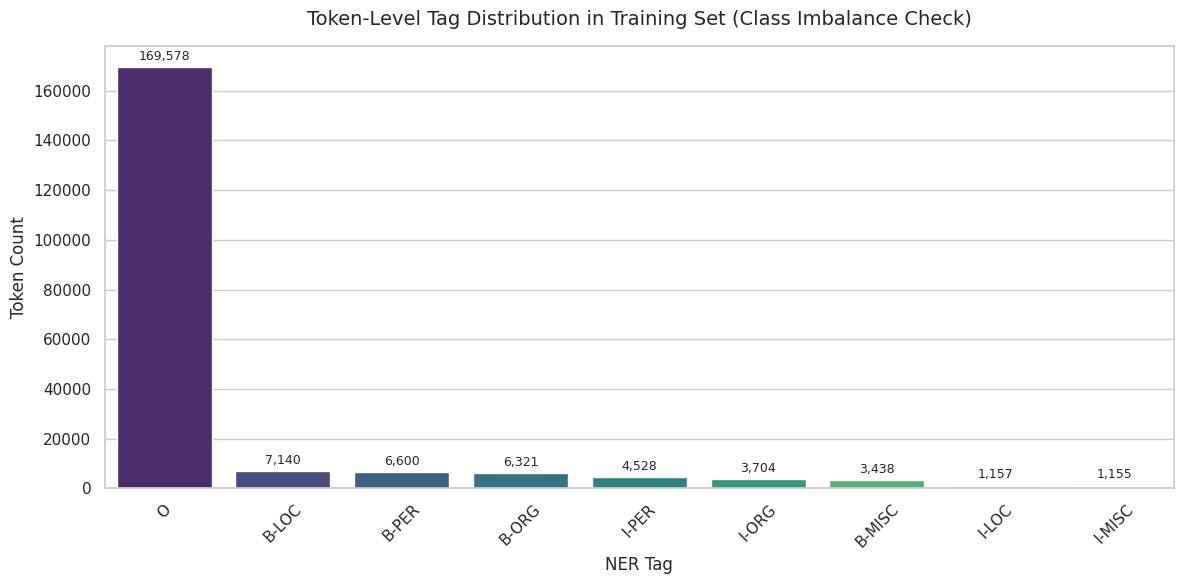

In [9]:
sns.set_theme(style="whitegrid")  # ضبط النمط العام للرسوم | Set global plot style
plt.figure(figsize=(12, 6))  # حجم الرسم | Figure size
ax = sns.barplot(x="Tag", y="Count", data=train_df, palette="viridis", hue="Tag", legend=False)  # رسم تكرارات كل الوسوم | Bar chart of all tag counts
plt.title("Token-Level Tag Distribution in Training Set (Class Imbalance Check)", fontsize=14, pad=15)  # العنوان | Title
plt.xlabel("NER Tag", fontsize=12)  # عنوان المحور السيني | X-axis label
plt.ylabel("Token Count", fontsize=12)  # عنوان المحور الصادي | Y-axis label
plt.xticks(rotation=45)  # تدوير أسماء الوسوم | Rotate tag names

for p in ax.patches:  # المرور على الأعمدة | Iterate over bars
    height = p.get_height()  # ارتفاع العمود | Bar height
    if height > 0:  # تجاهل الأعمدة الفارغة | Skip empty bars
        ax.annotate(f"{int(height):,}", (p.get_x() + p.get_width() / 2.0, height), ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")  # كتابة الرقم فوق العمود | Write the count above the bar

plt.tight_layout()  # ضبط الهوامش | Fix layout
plt.show()  # عرض الرسم | Show the plot

# Step 2: Entity-Only Distribution (Tokens & Spans)
# الخطوة 2: توزيع الكيانات فقط (توكنز وكيانات كاملة)

---

### 🎯 Objective / الهدف
- **EN:** Remove `O` to compare entity tags directly, and plot the number of complete entity spans per type next to it.
- **AR:** استبعاد `O` لمقارنة وسوم الكيانات مباشرة، مع رسم عدد الكيانات الكاملة لكل نوع بجانبه.

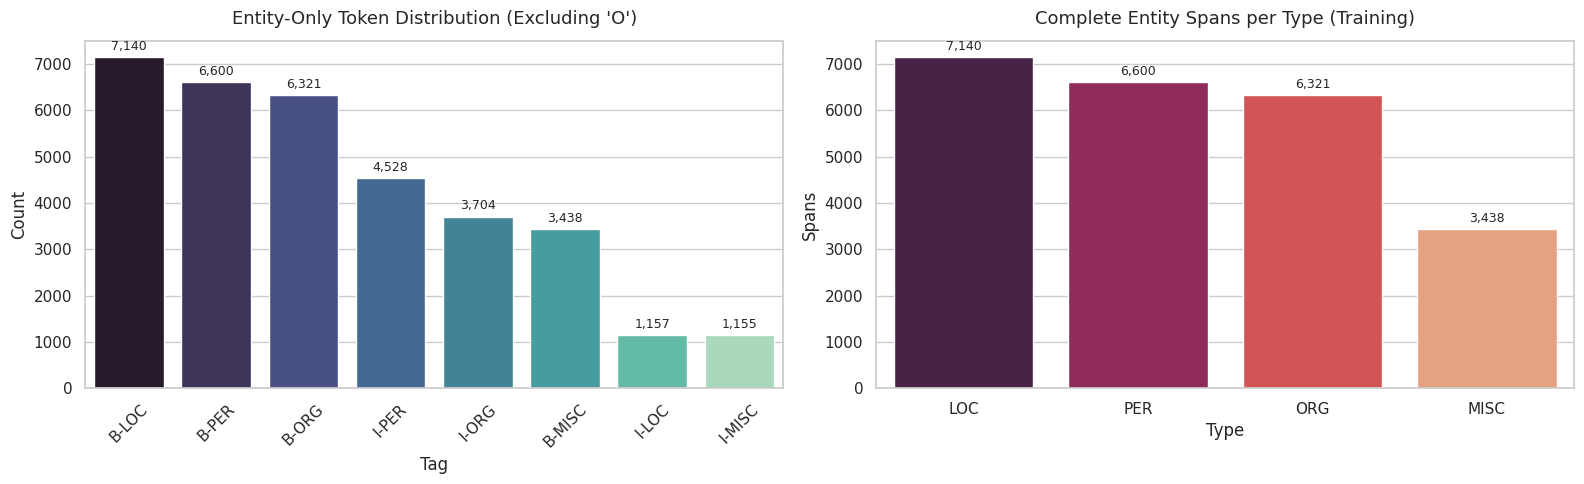

In [10]:
entities_df = train_df[train_df["Tag"] != "O"].copy()  # استبعاد كلاس O | Exclude the O class
span_df = pd.DataFrame({"Type": list(train_spans.keys()), "Spans": list(train_spans.values())}).sort_values("Spans", ascending=False)  # جدول الكيانات الكاملة | Span-count table

fig, axes = plt.subplots(1, 2, figsize=(16, 5))  # رسمان متجاوران | Two side-by-side plots

sns.barplot(x="Tag", y="Count", data=entities_df, palette="mako", hue="Tag", legend=False, ax=axes[0])  # رسم توكنز الكيانات | Entity token counts
axes[0].set_title("Entity-Only Token Distribution (Excluding 'O')", fontsize=13, pad=12)  # عنوان الرسم الأول | First plot title
axes[0].tick_params(axis="x", rotation=45)  # تدوير الأسماء | Rotate labels

sns.barplot(x="Type", y="Spans", data=span_df, palette="rocket", hue="Type", legend=False, ax=axes[1])  # رسم الكيانات الكاملة | Entity span counts
axes[1].set_title("Complete Entity Spans per Type (Training)", fontsize=13, pad=12)  # عنوان الرسم الثاني | Second plot title

for axis in axes:  # المرور على الرسمين | Iterate over both axes
    for p in axis.patches:  # المرور على الأعمدة | Iterate over bars
        if p.get_height() > 0:  # تجاهل الفارغ | Skip empty bars
            axis.annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2.0, p.get_height()), ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")  # كتابة الأرقام | Write counts

plt.tight_layout()  # ضبط الهوامش | Fix layout
plt.show()  # عرض الرسم | Show the plot

# 📊 Output Analysis: Entity-Only Distribution
# تحليل المخرجات: توزيع الكيانات فقط

---

### 🎯 Key Observations / الملاحظات الرئيسية
- **EN:**
  - `LOC`, `PER` and `ORG` spans are expected to be the most frequent; `MISC` the least. This ordering usually predicts the per-type F1 ordering later.
  - Multi-word tags (`I-PER`, `I-ORG`) reflect how often names span several words.
- **AR:**
  - المتوقع أن تكون كيانات `LOC` و`PER` و`ORG` الأكثر تكراراً و`MISC` الأقل، وهذا الترتيب غالباً يتنبأ بترتيب F1 لكل نوع لاحقاً.
  - الوسوم متعددة الكلمات (`I-PER` و`I-ORG`) تعكس كثرة الأسماء المركبة.

# Step 3: Visual Audit of a Sample Sentence
# الخطوة 3: الفحص البصري لعينة من الجمل

---

### 🎯 Objective / الهدف
- **EN:** Print an aligned token/tag table for the first training sentence that contains at least two entity types, to confirm parsing is correct.
- **AR:** طباعة جدول الكلمات والوسوم لأول جملة تدريب تحتوي على نوعين من الكيانات على الأقل، للتأكد من سلامة القراءة.

In [11]:
def pick_sample(data, min_types=2):  # دالة اختيار جملة غنية بالكيانات | Pick an entity-rich sentence
    for idx, sentence in enumerate(data):  # المرور على الجمل | Iterate sentences
        types = {tag[2:] for tag in sentence["tags"] if tag != "O"}  # أنواع الكيانات في الجملة | Entity types in the sentence
        if len(types) >= min_types:  # لو فيها نوعان أو أكثر | If it has enough types
            return idx  # إرجاع رقم الجملة | Return its index
    return 0  # احتياطي لو لم توجد | Fallback


sample_index = pick_sample(train_data)  # رقم العينة المختارة | Chosen sample index
sample_sentence = train_data[sample_index]  # الجملة المختارة | The chosen sentence
audit_df = pd.DataFrame({"Token": sample_sentence["tokens"], "NER Tag": sample_sentence["tags"]})  # جدول العرض | Display table
print(f"🔍 Sample Sentence Audit (train index {sample_index}):")  # عنوان العينة | Sample title
print("-" * 40)  # فاصل | Separator
print(audit_df.to_string(index=True))  # طباعة الجدول | Print the table

🔍 Sample Sentence Audit (train index 0):
----------------------------------------
     Token NER Tag
0       EU   B-ORG
1  rejects       O
2   German  B-MISC
3     call       O
4       to       O
5  boycott       O
6  British  B-MISC
7     lamb       O
8        .       O


# 📊 Output Analysis: Sample Sentence Audit
# تحليل المخرجات: الفحص البصري للعينة

---

### 🎯 Key Observations / الملاحظات الرئيسية
- **EN:** Every token must sit next to its own tag with no shift, and no `-DOCSTART-` row may appear (v1 showed it as the first row; it is now filtered out in Phase 1).
- **AR:** يجب أن تقع كل كلمة بجانب وسمها بدون أي إزاحة، ولا يظهر صف `-DOCSTART-` (النسخة الأولى كانت تعرضه كأول صف، وهو الآن محذوف في المرحلة الأولى).

# Phase 3: Tokenization & Label Alignment
# المرحلة الثالثة: التقطيع ومحاذاة الوسوم

---

### 🎯 Objective / الهدف العام
- **EN:** Load the DeBERTa-v3 tokenizer, prove that **no sentence is truncated**, and implement/verify the first-sub-word label alignment strategy.
- **AR:** تحميل مقطّع DeBERTa-v3 والتأكد من أن **أي جملة لا تُقص**، ثم تنفيذ والتحقق من استراتيجية إعطاء الوسم لأول جزء من الكلمة.

### ⚠️ Why it matters / لماذا هذا مهم
- **EN:** The tokenizer splits words into sub-words, so one word can become several tokens while having a single label. Wrong alignment silently corrupts training and evaluation.
- **AR:** المقطّع يقسّم الكلمات لأجزاء فرعية، فكلمة واحدة قد تصبح عدة توكنز بوسم واحد. أي محاذاة خاطئة تفسد التدريب والتقييم بصمت.

### 🎯 Part 1: DeBERTa-v3 Tokenizer Loading, Sub-word Inspection & Truncation Audit
### الجزء الأول: تحميل المقطّع وفحص الأجزاء الفرعية وفحص القص

In [12]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)  # تحميل مقطّع DeBERTa-v3 | Load the DeBERTa-v3 tokenizer
print(f"✅ Tokenizer loaded | fast: {tokenizer.is_fast} | vocab size: {len(tokenizer):,}")  # تأكيد التحميل | Confirm loading

sample_tokens = sample_sentence["tokens"]  # كلمات العينة | Words of the sample
sample_encoding = tokenizer(sample_tokens, is_split_into_words=True)  # تقطيع العينة | Tokenize the sample
sample_pieces = tokenizer.convert_ids_to_tokens(sample_encoding["input_ids"])  # التوكنز الفرعية كنصوص | Sub-word strings
print("\n🔤 Words     :", sample_tokens)  # الكلمات الأصلية | Original words
print("🧩 Sub-words :", sample_pieces)  # الأجزاء الفرعية | Sub-word pieces
print("🔗 word_ids  :", sample_encoding.word_ids())  # ربط الأجزاء بالكلمات | Map pieces to words


def subword_lengths(data):  # دالة حساب أطوال التوكنز الفرعية | Compute sub-word sequence lengths
    encoded = tokenizer([s["tokens"] for s in data], is_split_into_words=True)  # تقطيع كل الجمل دفعة واحدة | Tokenize all sentences at once
    return [len(ids) for ids in encoded["input_ids"]]  # طول كل جملة | Length of each sentence


print("\n🔎 Truncation audit (MAX_LENGTH =", MAX_LENGTH, ")")  # عنوان الفحص | Audit title
for split_name, split in [("Train", train_data), ("Validation", valid_data), ("Test", test_data)]:  # المرور على التقسيمات | Iterate splits
    lengths = subword_lengths(split)  # أطوال هذا التقسيم | Lengths for this split
    over = sum(1 for n in lengths if n > MAX_LENGTH)  # عدد الجمل الأطول من الحد | Sentences above the limit
    print(f"   {split_name:<10} max: {max(lengths):>4} | p99: {int(np.percentile(lengths, 99)):>3} | over limit: {over}")  # ملخص الأطوال | Length summary
    assert over == 0, f"{split_name}: {over} sentences would be truncated, raise MAX_LENGTH!"  # فشل لو وجد قص | Fail if truncation would occur
print("✅ No sentence is truncated")  # تأكيد عدم القص | Confirm no truncation

config.json:   0%|          | 0.00/579 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

spm.model: reconstructing file:   0%|          |  0.00B / 2.46MB            

spm.model: downloading bytes:           |  0.00B            

✅ Tokenizer loaded | fast: True | vocab size: 128,001

🔤 Words     : ['EU', 'rejects', 'German', 'call', 'to', 'boycott', 'British', 'lamb', '.']
🧩 Sub-words : ['[CLS]', '▁EU', '▁rejects', '▁German', '▁call', '▁to', '▁boycott', '▁British', '▁lamb', '▁.', '[SEP]']
🔗 word_ids  : [None, 0, 1, 2, 3, 4, 5, 6, 7, 8, None]

🔎 Truncation audit (MAX_LENGTH = 256 )
   Train      max:  148 | p99:  54 | over limit: 0
   Validation max:  130 | p99:  57 | over limit: 0
   Test       max:  137 | p99:  54 | over limit: 0
✅ No sentence is truncated


# 📊 Output Analysis: Tokenization & Sub-word Inspection
# تحليل المخرجات: التقطيع وفحص الأجزاء الفرعية

---

### 🎯 Key Observations / الملاحظات الرئيسية
- **Sub-word splitting / تقسيم الكلمات:**
  - **EN:** Rare names split into several pieces; `word_ids` maps each piece back to its word, and special tokens (`[CLS]`, `[SEP]`) map to `None`.
  - **AR:** الأسماء النادرة تنقسم لعدة أجزاء، و`word_ids` تربط كل جزء بكلمته، والتوكنز الخاصة (`[CLS]` و`[SEP]`) تأخذ `None`.
- **Truncation safety / سلامة القص:**
  - **EN:** If the audit passes, `MAX_LENGTH` never cuts words, so word-level evaluation covers **every** word. (A truncated word would vanish from both gold and prediction without any error.)
  - **AR:** نجاح الفحص يعني أن `MAX_LENGTH` لا يقص أي كلمة، فالتقييم على مستوى الكلمة يغطي **كل** الكلمات (الكلمة المقصوصة كانت ستختفي من الأصل والتنبؤ بلا أي خطأ).

### 🎯 Part 2: Label Alignment Function (First Sub-word Strategy)
### الجزء الثاني: دالة محاذاة الوسوم (استراتيجية أول جزء فرعي)

- **EN:** The first sub-word of each word receives the word's label; every other sub-word and special token receives `-100`, which the loss ignores.
- **AR:** أول جزء فرعي من كل كلمة يأخذ وسم الكلمة؛ وكل الأجزاء الأخرى والتوكنز الخاصة تأخذ `-100` فتتجاهلها دالة الخسارة.

In [13]:
def align_labels_with_tokens(labels, word_ids):  # محاذاة وسوم الكلمات مع التوكنز الفرعية | Align word labels with sub-word tokens
    aligned = []  # قائمة الوسوم المحاذاة | Aligned label list
    previous_word = None  # الكلمة السابقة | Previous word index
    for word_id in word_ids:  # المرور على كل توكن فرعي | Iterate over each sub-word token
        if word_id is None:  # توكن خاص مثل CLS و SEP | Special token such as CLS or SEP
            aligned.append(-100)  # تجاهله في الخسارة | Ignore it in the loss
        elif word_id != previous_word:  # أول جزء فرعي من كلمة جديدة | First sub-word of a new word
            aligned.append(labels[word_id])  # إعطاؤه وسم الكلمة | Give it the word label
        else:  # جزء فرعي ثانٍ أو أكثر | A continuation sub-word
            aligned.append(-100)  # تجاهله في الخسارة | Ignore it in the loss
        previous_word = word_id  # تحديث الكلمة السابقة | Update previous word
    return aligned  # إرجاع الوسوم المحاذاة | Return aligned labels


sample_label_ids = [label2id[t] for t in sample_sentence["tags"]]  # وسوم العينة كأرقام | Sample tags as ids
sample_aligned = align_labels_with_tokens(sample_label_ids, sample_encoding.word_ids())  # تطبيق المحاذاة | Apply alignment
print("Aligned labels:", sample_aligned)  # طباعة الناتج | Print the result

assert len(sample_aligned) == len(sample_encoding["input_ids"]), "Length mismatch after alignment!"  # تطابق الأطوال | Lengths must match
assert sum(1 for x in sample_aligned if x != -100) == len(sample_tokens), "Each word must keep exactly one label!"  # وسم واحد لكل كلمة | Exactly one label per word
print("✅ Alignment verified: one label per word, everything else = -100")  # تأكيد النجاح | Confirm success

Aligned labels: [-100, 2, 8, 1, 8, 8, 8, 1, 8, 8, -100]
✅ Alignment verified: one label per word, everything else = -100


# 📊 Output Analysis: Label Alignment Verification
# تحليل المخرجات: التحقق من المحاذاة

---

### 🎯 Key Observations / الملاحظات الرئيسية
- **EN:** The two assertions prove (1) aligned labels have the same length as the sub-word sequence and (2) every original word contributes **exactly one** training label, no matter how many sub-words it has.
- **AR:** التأكيدان يثبتان (1) تطابق طول الوسوم مع طول التوكنز الفرعية و(2) أن كل كلمة أصلية تعطي وسماً تدريبياً **واحداً بالضبط** مهما كان عدد أجزائها.

### 🎯 Part 3: Tabular Sanity Check (Before vs. After Alignment)
### الجزء الثالث: جدول المقارنة قبل وبعد المحاذاة

In [14]:
rows = []  # صفوف الجدول | Table rows
for position, (piece, word_id, label_id) in enumerate(zip(sample_pieces, sample_encoding.word_ids(), sample_aligned)):  # المرور على كل توكن | Iterate over each token
    rows.append({  # إضافة صف | Append a row
        "Pos": position,  # رقم التوكن | Token position
        "Sub-word": piece,  # الجزء الفرعي | Sub-word piece
        "Word ID": word_id if word_id is not None else "—",  # رقم الكلمة الأصلية | Original word index
        "Original Tag": sample_sentence["tags"][word_id] if word_id is not None else "—",  # الوسم الأصلي | Original tag
        "Aligned Label": id2label[label_id] if label_id != -100 else "-100 (ignored)",  # الوسم بعد المحاذاة | Label after alignment
    })  # نهاية الصف | End of row
print(pd.DataFrame(rows).to_string(index=False))  # طباعة الجدول | Print the table

 Pos Sub-word Word ID Original Tag  Aligned Label
   0    [CLS]       —            — -100 (ignored)
   1      ▁EU       0        B-ORG          B-ORG
   2 ▁rejects       1            O              O
   3  ▁German       2       B-MISC         B-MISC
   4    ▁call       3            O              O
   5      ▁to       4            O              O
   6 ▁boycott       5            O              O
   7 ▁British       6       B-MISC         B-MISC
   8    ▁lamb       7            O              O
   9       ▁.       8            O              O
  10    [SEP]       —            — -100 (ignored)


# 📊 Output Analysis: Sanity Check Verification
# تحليل المخرجات: نتائج الفحص

---

### 🎯 Key Observations / الملاحظات الرئيسية
- **EN:** Look for a word split into several sub-words: only its **first** piece shows a real label, the rest show `-100 (ignored)`. Special tokens at both ends are always `-100`.
- **AR:** ابحث عن كلمة انقسمت لعدة أجزاء: **أولها فقط** يحمل وسماً حقيقياً والباقي `-100 (ignored)`، والتوكنز الخاصة في الطرفين دائماً `-100`.

# Phase 4: Datasets, Modeling & Training
# المرحلة الرابعة: بناء الداتاسيت والنموذج والتدريب

---

### 🎯 Objective / الهدف العام
- **EN:** Build the PyTorch datasets (with **lowercase augmentation** for training only), initialize the model with dynamic label mappings, audit its health, then train with warmup + linear decay, gradient clipping, automatic best-checkpoint selection and early stopping.
- **AR:** بناء الداتاسيت (مع **تعزيز الحروف الصغيرة** للتدريب فقط)، وتهيئة النموذج بقواميس الوسوم، وفحص سلامته، ثم التدريب مع إحماء وتناقص خطي وقص الجراديانت واختيار أفضل نقطة تلقائياً وإيقاف مبكر.

### 🎯 Part 1: Dataset Class & DataLoaders
### الجزء الأول: كلاس الداتاسيت وتحميل الدفعات

- **EN:** `lower_prob` randomly lowercases whole training sentences so the model stops relying only on capitalization (the v1 Space returned no entity for `elon musk founded spacex in california`). Validation/test stay untouched.
- **AR:** `lower_prob` يحوّل جمل تدريب كاملة لحروف صغيرة عشوائياً حتى لا يعتمد النموذج على الحرف الكبير وحده (نسخة الـ Space الأولى لم تجد أي كيان في `elon musk founded spacex in california`). التحقق والاختبار يبقيان بدون تعديل.

In [15]:
class NERDataset(Dataset):  # كلاس الداتاسيت الخاص بمهمة NER | NER dataset class
    def __init__(self, data, tokenizer, label2id, lower_prob=0.0):  # المُنشئ مع نسبة التعزيز | Constructor with augmentation probability
        self.data = data  # تخزين الجمل | Store the sentences
        self.tokenizer = tokenizer  # تخزين المقطّع | Store the tokenizer
        self.label2id = label2id  # تخزين قاموس الوسوم | Store the label map
        self.lower_prob = lower_prob  # احتمال تحويل الجملة لحروف صغيرة | Probability of lowercasing a sentence

    def __len__(self):  # عدد العينات | Number of samples
        return len(self.data)  # إرجاع الطول | Return the length

    def __getitem__(self, idx):  # جلب عينة واحدة | Fetch one sample
        item = self.data[idx]  # العينة الخام | Raw sample
        words = item["tokens"]  # كلمات الجملة | Sentence words
        if self.lower_prob > 0 and np.random.rand() < self.lower_prob:  # قرار عشوائي للتحويل | Random lowercase decision
            words = [w.lower() for w in words]  # تحويل الكلمات لحروف صغيرة | Lowercase every word
        encoding = self.tokenizer(words, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)  # تقطيع الجملة | Tokenize the sentence
        label_ids = [self.label2id[t] for t in item["tags"]]  # الوسوم كأرقام | Tags as ids
        encoding["labels"] = align_labels_with_tokens(label_ids, encoding.word_ids())  # محاذاة الوسوم | Align labels
        return dict(encoding)  # إرجاع قاموس عادي | Return a plain dict


train_dataset = NERDataset(train_data, tokenizer, label2id, lower_prob=LOWER_PROB)  # داتاسيت التدريب مع التعزيز | Training dataset with augmentation
val_dataset = NERDataset(valid_data, tokenizer, label2id)  # داتاسيت التحقق الرسمي | Official validation dataset
data_collator = DataCollatorForTokenClassification(tokenizer=tokenizer)  # حشو ديناميكي للدفعات | Dynamic padding collator

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=data_collator)  # لودر التدريب | Training loader
val_loader = DataLoader(val_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=data_collator)  # لودر التحقق | Validation loader

check_batch = next(iter(train_loader))  # سحب دفعة للفحص | Pull one batch for inspection
print(f"✅ Train: {len(train_dataset):,} sentences, {len(train_loader):,} batches | Validation: {len(val_dataset):,} sentences")  # ملخص الداتا | Data summary
print("🧪 Batch shapes:", {k: tuple(v.shape) for k, v in check_batch.items()})  # أشكال الدفعة | Batch tensor shapes

✅ Train: 14,041 sentences, 878 batches | Validation: 3,250 sentences
🧪 Batch shapes: {'input_ids': (16, 44), 'token_type_ids': (16, 44), 'attention_mask': (16, 44), 'labels': (16, 44)}


### 🎯 Part 2: Model Initialization with Dynamic Label Mappings
### الجزء الثاني: تهيئة النموذج بقواميس الوسوم الديناميكية

In [16]:
config = AutoConfig.from_pretrained(MODEL_NAME, num_labels=len(label2id), id2label=id2label, label2id=label2id)  # إعدادات النموذج مع الوسوم | Config with label maps
model = AutoModelForTokenClassification.from_pretrained(MODEL_NAME, config=config, dtype=torch.float32).to(device)  # تحميل النموذج بدقة كاملة ونقله للجهاز | Load the model in full fp32 precision and move it to the device

total_params = sum(p.numel() for p in model.parameters())  # إجمالي المعاملات | Total parameters
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)  # المعاملات القابلة للتدريب | Trainable parameters
print(f"🧠 Model: {MODEL_NAME} | params: {total_params / 1e6:.1f}M | trainable: {trainable_params / 1e6:.1f}M")  # ملخص النموذج | Model summary
print(f"🏷️ Classifier head: {model.classifier} | labels: {model.config.id2label}")  # رأس التصنيف والوسوم | Head and label map
assert next(model.parameters()).dtype == torch.float32, "Model is NOT fp32: AdamW will produce NaN (eps underflows in half precision)!"  # الأوزان لازم تكون fp32 | Weights must be fp32
assert model.config.num_labels == len(unique_labels), "num_labels mismatch!"  # تطابق عدد الوسوم | Label count must match
assert {int(k): v for k, v in model.config.id2label.items()} == id2label, "id2label mismatch!"  # تطابق القاموس | Label map must match

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  371MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForTokenClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task

model.safetensors: reconstructing file:   0%|          |  0.00B /  371MB            

model.safetensors: downloading bytes:           |  0.00B            

🧠 Model: microsoft/deberta-v3-base | params: 183.8M | trainable: 183.8M
🏷️ Classifier head: Linear(in_features=768, out_features=9, bias=True) | labels: {0: 'B-LOC', 1: 'B-MISC', 2: 'B-ORG', 3: 'B-PER', 4: 'I-LOC', 5: 'I-MISC', 6: 'I-ORG', 7: 'I-PER', 8: 'O'}


# 📊 Output Analysis: Model Architecture & Label Mapping
# تحليل المخرجات: بنية النموذج وقواميس الوسوم

---

### 🎯 Key Observations / الملاحظات الرئيسية
- **EN:** The pretrained encoder is reused and only a fresh linear classification head (`hidden_size → 9`) is randomly initialized; the transformers warning about newly initialized `classifier` weights is expected. The assertions confirm the model's `id2label` is identical to the locked schema. **`dtype=torch.float32` is mandatory:** recent `transformers` versions load weights in the checkpoint's stored dtype by default, and half-precision weights make AdamW return NaN after the first update (its `eps=1e-8` underflows to 0), which is exactly what the first v2 run hit.
- **AR:** يُعاد استخدام الـ encoder المدرب مسبقاً ويُهيأ عشوائياً رأس تصنيف خطي جديد فقط (`hidden_size → 9`)؛ وتحذير transformers عن أوزان `classifier` الجديدة متوقع. التأكيدات تثبت تطابق `id2label` في النموذج مع المخطط المقفول. **ضبط `dtype=torch.float32` إلزامي:** نسخ `transformers` الحديثة تحمّل الأوزان بنوعها المخزن في الـ checkpoint افتراضياً، والأوزان نصف الدقة تجعل AdamW يعطي NaN بعد أول تحديث (لأن `eps=1e-8` يتصفّر)، وهذا بالضبط ما حدث في أول تشغيل للنسخة الثانية.

### 🎯 Part 3: Pre-Training Stability Audit
### الجزء الثالث: فحص الاستقرار قبل التدريب

In [17]:
print("🔍 RUNNING PRE-TRAINING STABILITY & SAFETY CHECKS")  # عنوان الفحص | Audit title
bad_params = [name for name, p in model.named_parameters() if torch.isnan(p).any() or torch.isinf(p).any()]  # معاملات فيها NaN أو Inf | Parameters with NaN or Inf
assert not bad_params, f"NaN/Inf found in: {bad_params[:5]}"  # فشل لو وجدت | Fail if any exist
print("✅ No NaN/Inf in model weights")  # تأكيد سلامة الأوزان | Weights are healthy
assert all(p.dtype == torch.float32 for p in model.parameters()), "Some parameters are not fp32!"  # كل الأوزان fp32 | All parameters must be fp32
print("✅ All parameters are float32")  # تأكيد الدقة | Confirm the precision

max_input_id = int(check_batch["input_ids"].max())  # أكبر رقم توكن في الدفعة | Largest token id in the batch
vocab_size = model.get_input_embeddings().num_embeddings  # حجم قاموس الـ embeddings | Embedding vocabulary size
assert max_input_id < vocab_size, "Token id exceeds embedding table!"  # الأرقام ضمن النطاق | Ids must be in range
print(f"✅ Max input id {max_input_id:,} < embedding vocab {vocab_size:,}")  # تأكيد النطاق | Confirm range

valid_labels = check_batch["labels"][check_batch["labels"] != -100]  # الوسوم الحقيقية فقط | Real labels only
assert int(valid_labels.max()) < len(label2id) and int(valid_labels.min()) >= 0, "Label id out of range!"  # الوسوم ضمن النطاق | Labels must be in range
print(f"✅ Label ids in [0, {len(label2id) - 1}]")  # تأكيد الوسوم | Confirm labels

model.eval()  # وضع التقييم لفحص أولي | Eval mode for a probe pass
with torch.no_grad():  # بدون جراديانت | No gradients
    probe = model(input_ids=check_batch["input_ids"].to(device), attention_mask=check_batch["attention_mask"].to(device), labels=check_batch["labels"].to(device))  # تمرير تجريبي | Probe forward pass
expected_loss = float(np.log(len(label2id)))  # خسارة التخمين العشوائي المتوقعة | Expected random-guess loss
print(f"✅ Probe loss {probe.loss.item():.3f} (random-guess reference ≈ {expected_loss:.3f})")  # مقارنة الخسارة | Compare the loss
assert torch.isfinite(probe.loss), "Initial loss is not finite!"  # الخسارة لازم تكون رقماً سليماً | Loss must be finite

🔍 RUNNING PRE-TRAINING STABILITY & SAFETY CHECKS
✅ No NaN/Inf in model weights
✅ All parameters are float32
✅ Max input id 118,884 < embedding vocab 128,100
✅ Label ids in [0, 8]
✅ Probe loss 2.177 (random-guess reference ≈ 2.197)


# 📊 Output Analysis: Pre-Training Stability & Safety Audit
# تحليل المخرجات: فحص الاستقرار والسلامة قبل التدريب

---

### 🎯 Key Observations / الملاحظات الرئيسية
- **EN:** The probe loss of an untrained head should be in the neighbourhood of `ln(9) ≈ 2.2` (random guessing); a value wildly different signals a label or alignment bug that is far cheaper to catch now than after a full training run.
- **AR:** خسارة الفحص لرأس غير مدرب يجب أن تكون قريبة من `ln(9) ≈ 2.2` (تخمين عشوائي)؛ وأي قيمة بعيدة جداً تدل على خطأ في الوسوم أو المحاذاة، واكتشافه الآن أرخص بكثير من اكتشافه بعد تدريب كامل.

### 🎯 Part 4: Shared Evaluation Helper
### الجزء الرابع: دالة التقييم المشتركة

- **EN:** One shared `evaluate` function (v1 defined it twice) returns loss, entity-level P/R/F1, token accuracy and the word-level label lists.
- **AR:** دالة `evaluate` واحدة مشتركة (النسخة الأولى عرّفتها مرتين) ترجع الخسارة ومقاييس الكيان والدقة وقوائم الوسوم على مستوى الكلمة.

In [18]:
def evaluate(model, loader, id2label):  # دالة تقييم موحدة | Single shared evaluation function
    model.eval()  # وضع التقييم | Evaluation mode
    total_loss = 0.0  # مجموع الخسارة | Loss accumulator
    y_true = []  # الوسوم الحقيقية لكل جملة | Gold labels per sentence
    y_pred = []  # الوسوم المتوقعة لكل جملة | Predicted labels per sentence

    with torch.no_grad():  # بدون جراديانت | No gradients
        for batch in tqdm(loader, desc="Evaluating", leave=False):  # المرور على الدفعات | Iterate over batches
            input_ids = batch["input_ids"].to(device)  # المدخلات | Input ids
            attention_mask = batch["attention_mask"].to(device)  # قناع الانتباه | Attention mask
            labels = batch["labels"].to(device)  # الوسوم | Labels
            outputs = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels)  # تمرير أمامي | Forward pass
            total_loss += outputs.loss.item()  # تجميع الخسارة | Accumulate loss
            predictions = outputs.logits.argmax(dim=-1)  # أعلى احتمال لكل توكن | Highest-probability class per token

            for i in range(labels.size(0)):  # المرور على جمل الدفعة | Iterate over sentences in the batch
                mask = labels[i] != -100  # التوكنز الحقيقية فقط (أول جزء من كل كلمة) | Real tokens only (first sub-word of each word)
                y_true.append([id2label[x] for x in labels[i][mask].tolist()])  # حفظ الوسوم الحقيقية | Store gold labels
                y_pred.append([id2label[x] for x in predictions[i][mask].tolist()])  # حفظ الوسوم المتوقعة | Store predictions

    return {  # إرجاع كل المقاييس | Return all metrics
        "loss": total_loss / len(loader),  # متوسط الخسارة | Mean loss
        "precision": precision_score(y_true, y_pred),  # الدقة على مستوى الكيان | Entity-level precision
        "recall": recall_score(y_true, y_pred),  # الاستدعاء على مستوى الكيان | Entity-level recall
        "f1": f1_score(y_true, y_pred),  # F1 على مستوى الكيان | Entity-level F1
        "accuracy": accuracy_score(y_true, y_pred),  # دقة التوكنز | Token accuracy
        "y_true": y_true,  # الوسوم الحقيقية | Gold labels
        "y_pred": y_pred,  # الوسوم المتوقعة | Predictions
    }  # نهاية القاموس | End of dictionary

### 🎯 Part 5: Guarded Training Loop (Fresh Start, NaN Protection, Best Checkpoint, Early Stopping)
### الجزء الخامس: حلقة التدريب المحمية (بداية نظيفة وحماية من NaN وأفضل نقطة وإيقاف مبكر)

- **EN:** The cell **re-initializes the model, optimizer and scheduler every time it runs**, so a run that went bad can never poison the next one. Before each update it checks that the loss and the gradient norm are finite and **skips** the step otherwise (`clip_grad_norm_` multiplies *all* gradients by a NaN/inf factor, so a single bad batch would otherwise destroy every weight permanently). The first bad batch is printed for diagnosis, and training aborts if too many steps are skipped.
- **AR:** الخلية **تعيد تهيئة النموذج والمحسّن والجدولة في كل مرة تُشغَّل**، فلا يمكن لتشغيل فاسد أن يلوّث الذي بعده. وقبل كل تحديث تتأكد أن الخسارة ونورم الجراديانت أرقام سليمة وإلا **تتخطى** الخطوة (لأن `clip_grad_norm_` يضرب *كل* الجراديانت في معامل NaN/inf فتدمر دفعة واحدة سيئة كل الأوزان للأبد). وتُطبع أول دفعة سيئة للتشخيص، ويتوقف التدريب لو زادت الخطوات المتخطاة عن الحد.

In [19]:
set_seed(SEED)  # إعادة تثبيت العشوائية لتكرار التشغيل | Re-seed so re-runs are reproducible
model = AutoModelForTokenClassification.from_pretrained(MODEL_NAME, config=config, dtype=torch.float32).to(device)  # نموذج جديد نظيف بدقة fp32 | Brand-new clean fp32 model
assert next(model.parameters()).dtype == torch.float32, "Model is not fp32!"  # حماية من النص دقة | Guard against half precision
print(f"🔢 Parameter dtype: {next(model.parameters()).dtype}")  # عرض نوع الأوزان | Show the weight dtype

no_decay = ["bias", "LayerNorm.weight"]  # معاملات بلا weight decay | Parameters excluded from weight decay
parameter_groups = [  # مجموعتا معاملات | Two parameter groups
    {"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": WEIGHT_DECAY},  # مجموعة بتنظيم | Group with decay
    {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0},  # مجموعة بدون تنظيم | Group without decay
]  # نهاية المجموعات | End of groups
optimizer = AdamW(parameter_groups, lr=LEARNING_RATE)  # محسّن جديد | Fresh optimizer
total_steps = len(train_loader) * NUM_EPOCHS  # إجمالي خطوات التدريب | Total training steps
warmup_steps = int(WARMUP_RATIO * total_steps)  # خطوات الإحماء | Warmup steps
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=warmup_steps, num_training_steps=total_steps)  # جدولة جديدة | Fresh LR schedule
print(f"⚙️ AdamW lr={LEARNING_RATE} | warmup {warmup_steps:,} / total {total_steps:,} steps | epochs ≤ {NUM_EPOCHS} (patience {PATIENCE})")  # ملخص الإعدادات | Settings summary

os.makedirs(BEST_DIR, exist_ok=True)  # إنشاء مجلد أفضل نموذج | Create the best-model folder
history = []  # سجل المقاييس لكل إيبوك | Per-epoch metrics log
best_f1 = -1.0  # أفضل F1 حتى الآن | Best F1 so far
best_epoch = 0  # رقم أفضل إيبوك | Best epoch number
epochs_without_improvement = 0  # عداد الإيبوكات بلا تحسن | Epochs without improvement
skipped_steps = 0  # عدد الخطوات المتخطاة | Number of skipped steps
first_bad_report = None  # تقرير أول دفعة سيئة | Report on the first bad batch


def report_bad_step(reason, epoch, step, batch, loss_value, grad_norm_value):  # دالة طباعة تشخيص الدفعة السيئة | Print a diagnosis of a bad batch
    print(f"\n⚠️ Skipped step | {reason} | epoch {epoch}, step {step} | loss={loss_value} | grad_norm={grad_norm_value}")  # سبب التخطي | Why it was skipped
    print(f"   batch shape {tuple(batch['input_ids'].shape)} | max input id {int(batch['input_ids'].max())} | label ids {sorted(set(batch['labels'].unique().tolist()))}")  # معلومات الدفعة | Batch info
    print(f"   first sentence: {tokenizer.decode(batch['input_ids'][0], skip_special_tokens=True)[:150]}")  # أول جملة في الدفعة | First sentence in the batch


for epoch in range(1, NUM_EPOCHS + 1):  # حلقة الإيبوكات | Epoch loop
    model.train()  # وضع التدريب | Training mode
    running_loss = 0.0  # مجموع خسارة الإيبوك | Epoch loss accumulator
    good_steps = 0  # عدد الخطوات السليمة | Number of healthy steps
    progress = tqdm(train_loader, desc=f"Epoch {epoch}/{NUM_EPOCHS} [train]")  # شريط التقدم | Progress bar

    for step, batch in enumerate(progress, 1):  # المرور على الدفعات | Iterate over batches
        input_ids = batch["input_ids"].to(device)  # المدخلات | Input ids
        attention_mask = batch["attention_mask"].to(device)  # قناع الانتباه | Attention mask
        labels = batch["labels"].to(device)  # الوسوم | Labels

        optimizer.zero_grad()  # تصفير الجراديانت | Zero the gradients
        loss = model(input_ids=input_ids, attention_mask=attention_mask, labels=labels).loss  # حساب الخسارة | Compute the loss

        if not torch.isfinite(loss):  # لو الخسارة NaN أو inf | If the loss is NaN or inf
            skipped_steps += 1  # عد الخطوة المتخطاة | Count the skipped step
            if first_bad_report is None:  # أول مرة تحصل | First occurrence
                first_bad_report = (epoch, step)  # تسجيل مكانها | Record where it happened
                report_bad_step("non-finite LOSS in forward pass", epoch, step, batch, loss.item(), "n/a")  # طباعة التشخيص | Print the diagnosis
            if skipped_steps >= MAX_SKIPPED_STEPS:  # لو تخطينا كثيراً | If too many steps were skipped
                raise RuntimeError(f"Aborting: {skipped_steps} non-finite steps. See the first-bad-batch report above.")  # إيقاف صريح | Explicit abort
            continue  # تخطي هذه الدفعة | Skip this batch

        loss.backward()  # الانتشار العكسي | Backpropagation
        grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), MAX_GRAD_NORM)  # قص الجراديانت وإرجاع نورمها | Clip gradients and return their norm

        if not torch.isfinite(grad_norm):  # لو الجراديانت NaN أو inf | If gradients are NaN or inf
            skipped_steps += 1  # عد الخطوة المتخطاة | Count the skipped step
            optimizer.zero_grad()  # مسح الجراديانت الفاسدة | Discard the corrupted gradients
            if first_bad_report is None:  # أول مرة تحصل | First occurrence
                first_bad_report = (epoch, step)  # تسجيل مكانها | Record where it happened
                report_bad_step("non-finite GRADIENT norm", epoch, step, batch, loss.item(), float(grad_norm))  # طباعة التشخيص | Print the diagnosis
            if skipped_steps >= MAX_SKIPPED_STEPS:  # لو تخطينا كثيراً | If too many steps were skipped
                raise RuntimeError(f"Aborting: {skipped_steps} non-finite steps. See the first-bad-batch report above.")  # إيقاف صريح | Explicit abort
            continue  # تخطي التحديث بدون لمس الأوزان | Skip the update, weights untouched

        optimizer.step()  # تحديث الأوزان | Update the weights
        scheduler.step()  # تحديث معدل التعلم | Update the learning rate
        running_loss += loss.item()  # تجميع الخسارة | Accumulate the loss
        good_steps += 1  # عد الخطوة السليمة | Count the healthy step
        progress.set_postfix(loss=f"{loss.item():.4f}", gnorm=f"{float(grad_norm):.2f}", skipped=skipped_steps)  # عرض الحالة | Show the status

    assert good_steps > 0, "No healthy step in this epoch!"  # لازم خطوات سليمة | Healthy steps are required
    train_loss = running_loss / good_steps  # متوسط خسارة التدريب | Mean training loss
    val = evaluate(model, val_loader, id2label)  # تقييم على التحقق الرسمي | Evaluate on official validation
    assert np.isfinite(val["loss"]), "Validation loss is NaN: the weights are corrupted, do not trust this run!"  # فحص سلامة الأوزان | Weight health check
    history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val["loss"], "val_precision": val["precision"], "val_recall": val["recall"], "val_f1": val["f1"], "val_accuracy": val["accuracy"], "skipped_steps": skipped_steps})  # تسجيل المقاييس | Log the metrics
    print(f"📈 Epoch {epoch} | train loss {train_loss:.4f} | val loss {val['loss']:.4f} | val P {val['precision']:.4f} R {val['recall']:.4f} F1 {val['f1']:.4f} | skipped so far: {skipped_steps}")  # طباعة الملخص | Print the summary

    if val["f1"] > best_f1:  # لو ده أفضل F1 | If this is the best F1
        best_f1 = val["f1"]  # تحديث الأفضل | Update best score
        best_epoch = epoch  # تحديث رقم الإيبوك | Update best epoch
        epochs_without_improvement = 0  # تصفير عداد الصبر | Reset patience counter
        model.save_pretrained(BEST_DIR)  # حفظ الموديل تلقائياً | Auto-save the model
        tokenizer.save_pretrained(BEST_DIR)  # حفظ المقطّع | Save the tokenizer
        print(f"   💾 New best model saved (epoch {epoch}, val F1 {best_f1:.4f})")  # تأكيد الحفظ | Confirm the save
    else:  # لو مفيش تحسن | If no improvement
        epochs_without_improvement += 1  # زيادة عداد الصبر | Increase the patience counter
        if epochs_without_improvement >= PATIENCE:  # لو الصبر خلص | If patience is exhausted
            print(f"⏹️ Early stopping at epoch {epoch} (no improvement for {PATIENCE} epochs)")  # رسالة الإيقاف | Stopping message
            break  # إنهاء التدريب | Stop training

print(f"\n🏁 Training finished | best epoch: {best_epoch} | best val F1: {best_f1:.4f} | skipped steps: {skipped_steps}")  # ملخص التدريب | Training summary

Loading weights:   0%|          | 0/198 [00:00<?, ?it/s]

[transformers] DebertaV2ForTokenClassification LOAD REPORT from: microsoft/deberta-v3-base
Key                                     | Status     | 
----------------------------------------+------------+-
lm_predictions.lm_head.bias             | UNEXPECTED | 
mask_predictions.LayerNorm.weight       | UNEXPECTED | 
mask_predictions.dense.bias             | UNEXPECTED | 
mask_predictions.dense.weight           | UNEXPECTED | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED | 
mask_predictions.LayerNorm.bias         | UNEXPECTED | 
mask_predictions.classifier.weight      | UNEXPECTED | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED | 
mask_predictions.classifier.bias        | UNEXPECTED | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED | 
classifier.weight                       | MISSING    | 
classifier.bias                         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task

🔢 Parameter dtype: torch.float32
⚙️ AdamW lr=2e-05 | warmup 439 / total 4,390 steps | epochs ≤ 5 (patience 2)


Epoch 1/5 [train]:   0%|          | 0/878 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/102 [00:00<?, ?it/s]

📈 Epoch 1 | train loss 0.3184 | val loss 0.0361 | val P 0.9365 R 0.9505 F1 0.9435 | skipped so far: 0


... (18 outputs left out)

Evaluating:   0%|          | 0/102 [00:00<?, ?it/s]

📈 Epoch 5 | train loss 0.0145 | val loss 0.0314 | val P 0.9575 R 0.9667 F1 0.9621 | skipped so far: 0


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   💾 New best model saved (epoch 5, val F1 0.9621)

🏁 Training finished | best epoch: 5 | best val F1: 0.9621 | skipped steps: 0


### 🎯 Part 6: Training Curves & Backup
### الجزء السادس: منحنيات التدريب والنسخ الاحتياطي

- **EN:** Plot loss and validation F1 per epoch, save the history, and back up the best model to Drive because the Colab runtime is ephemeral.
- **AR:** رسم الخسارة وF1 لكل إيبوك وحفظ السجل ونسخ أفضل نموذج للدرايف احتياطياً لأن بيئة كولاب مؤقتة.

 epoch  train_loss  val_loss  val_precision  val_recall  val_f1  val_accuracy  skipped_steps
     1      0.3184    0.0361         0.9365      0.9505  0.9435        0.9901              0
     2      0.0419    0.0327         0.9499      0.9613  0.9556        0.9921              0
     3      0.0264    0.0312         0.9548      0.9638  0.9593        0.9927              0
     4      0.0193    0.0315         0.9556      0.9633  0.9594        0.9929              0
     5      0.0145    0.0314         0.9575      0.9667  0.9621        0.9932              0


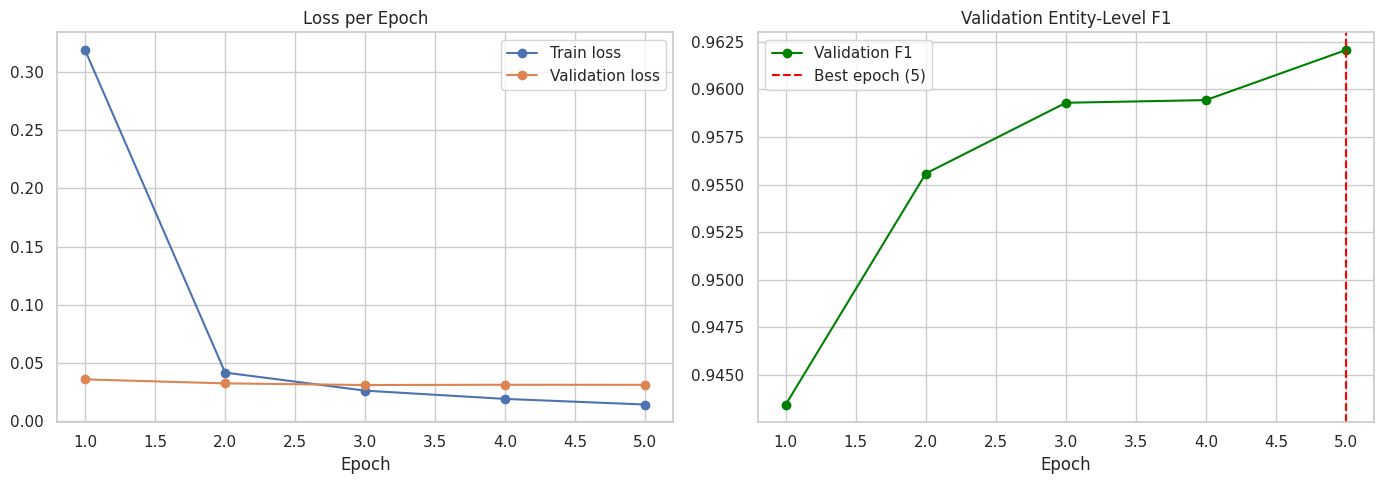

💾 Best model backed up to: /content/drive/MyDrive/ner_best_model


In [20]:
history_df = pd.DataFrame(history)  # تحويل السجل لجدول | Convert the log to a table
print(history_df.round(4).to_string(index=False))  # طباعة الجدول | Print the table

fig, axes = plt.subplots(1, 2, figsize=(14, 5))  # رسمان متجاوران | Two side-by-side plots
axes[0].plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train loss")  # منحنى خسارة التدريب | Training loss curve
axes[0].plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation loss")  # منحنى خسارة التحقق | Validation loss curve
axes[0].set_title("Loss per Epoch")  # عنوان الرسم الأول | First plot title
axes[0].set_xlabel("Epoch")  # محور الإيبوك | Epoch axis
axes[0].legend()  # إظهار المفتاح | Show legend
axes[1].plot(history_df["epoch"], history_df["val_f1"], marker="o", color="green", label="Validation F1")  # منحنى F1 | F1 curve
axes[1].axvline(best_epoch, color="red", linestyle="--", label=f"Best epoch ({best_epoch})")  # خط أفضل إيبوك | Best-epoch marker
axes[1].set_title("Validation Entity-Level F1")  # عنوان الرسم الثاني | Second plot title
axes[1].set_xlabel("Epoch")  # محور الإيبوك | Epoch axis
axes[1].legend()  # إظهار المفتاح | Show legend
plt.tight_layout()  # ضبط الهوامش | Fix layout
plt.savefig(os.path.join(CHECKPOINT_DIR, "training_curves.png"), dpi=150)  # حفظ الصورة | Save the figure
plt.show()  # عرض الرسم | Show the plot

history_df.to_csv(os.path.join(CHECKPOINT_DIR, "training_history.csv"), index=False)  # حفظ السجل كملف CSV | Save the history as CSV
shutil.copytree(BEST_DIR, DRIVE_MODEL_DIR, dirs_exist_ok=True)  # نسخ أفضل نموذج للدرايف | Back up the best model to Drive
shutil.copy(os.path.join(CHECKPOINT_DIR, "training_history.csv"), "/content/drive/MyDrive/ner_training_history.csv")  # نسخ السجل للدرايف | Back up the history to Drive
print(f"💾 Best model backed up to: {DRIVE_MODEL_DIR}")  # تأكيد النسخ | Confirm the backup

# 📊 Output Analysis: Training Dynamics
# تحليل المخرجات: ديناميكية التدريب

---

### 🎯 How to Read the Curves / كيف تقرأ المنحنيات
- **EN:**
  - Training loss should fall steadily; validation loss typically bottoms out within the first few epochs.
  - **Validation F1 is the selection criterion**, not validation loss; the two can disagree slightly and F1 matches the final metric.
  - If validation loss climbs while F1 stays flat, the model is starting to overfit and early stopping is doing its job.
- **AR:**
  - خسارة التدريب يجب أن تنزل بثبات، وخسارة التحقق عادة تصل لأدنى قيمة في أول إيبوكات.
  - **معيار الاختيار هو F1 على التحقق** وليس خسارة التحقق؛ وقد يختلفان قليلاً، وF1 هو الأقرب للمقياس النهائي.
  - لو ارتفعت خسارة التحقق وF1 ثابت فالنموذج بدأ يحفظ بيانات التدريب، والإيقاف المبكر يؤدي دوره.

# Phase 5: Final Evaluation on the Test Set
# المرحلة الخامسة: التقييم النهائي على مجموعة الاختبار

---

### 🎯 Objective / الهدف العام
- **EN:** Reload the best checkpoint from disk, evaluate it **once** on the untouched test set (no decision was based on test data), then stress-test robustness to casing, inspect the token-level confusion matrix, and read real error examples.
- **AR:** إعادة تحميل أفضل نقطة حفظ من القرص، وتقييمها **مرة واحدة** على مجموعة الاختبار التي لم تُستخدم في أي قرار، ثم اختبار المتانة مع اختلاف حالة الأحرف، وفحص مصفوفة الإرباك، وقراءة أمثلة أخطاء حقيقية.

### 🛡️ Step 1: Reload Best Model & Safety Check on `id2label`
### الخطوة 1: إعادة تحميل أفضل نموذج والتحقق من قاموس الوسوم

In [21]:
best_model = AutoModelForTokenClassification.from_pretrained(BEST_DIR, dtype=torch.float32).to(device)  # تحميل أفضل نموذج بدقة fp32 | Load the best model in fp32
best_tokenizer = AutoTokenizer.from_pretrained(BEST_DIR)  # تحميل المقطّع المحفوظ معه | Load its saved tokenizer

loaded_id2label = {int(k): v for k, v in best_model.config.id2label.items()}  # قاموس الوسوم من النموذج المحمل | id2label from the reloaded model
assert loaded_id2label == id2label, "id2label of the saved model differs from the locked schema!"  # مطابقة المخطط المقفول | Must match the locked schema
print(f"✅ Reloaded best model (epoch {best_epoch}) | id2label identical to the locked schema")  # تأكيد النجاح | Confirm success

test_dataset = NERDataset(test_data, best_tokenizer, label2id)  # داتاسيت الاختبار بدون تعزيز | Test dataset without augmentation
test_lower_dataset = NERDataset(test_data, best_tokenizer, label2id, lower_prob=1.0)  # نسخة الاختبار كلها حروف صغيرة | Fully lowercased test copy
test_loader = DataLoader(test_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=data_collator)  # لودر الاختبار | Test loader
test_lower_loader = DataLoader(test_lower_dataset, batch_size=EVAL_BATCH_SIZE, shuffle=False, collate_fn=data_collator)  # لودر الاختبار الصغير | Lowercased test loader
print(f"🧪 Test sentences: {len(test_dataset):,}")  # عدد جمل الاختبار | Number of test sentences

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

✅ Reloaded best model (epoch 5) | id2label identical to the locked schema
🧪 Test sentences: 3,453


### 📊 Step 2: Entity-Level Evaluation using `seqeval`
### الخطوة 2: التقييم الحقيقي على مستوى الكيان باستخدام `seqeval`

- **EN:** An entity counts as correct only if **both its boundaries and its type** match exactly. Test sentences are evaluated in their original order, with every word covered (the truncation audit guarantees it).
- **AR:** يُحسب الكيان صحيحاً فقط إذا تطابقت **حدوده ونوعه** معاً تماماً. تُقيَّم جمل الاختبار بترتيبها الأصلي مع تغطية كل الكلمات (فحص القص يضمن ذلك).

In [22]:
test_result = evaluate(best_model, test_loader, id2label)  # تقييم النموذج على الاختبار | Evaluate on the test set
y_true, y_pred = test_result["y_true"], test_result["y_pred"]  # الوسوم الحقيقية والمتوقعة | Gold and predicted labels

assert all(len(t) == len(s["tokens"]) for t, s in zip(y_true, test_data)), "A sentence lost words during evaluation!"  # كل كلمة مُقيَّمة | Every word must be evaluated
n_gold_entities = len(get_entities(y_true))  # عدد الكيانات الحقيقية | Number of gold entities
print("=" * 60)  # فاصل | Separator
print("🏆 TEST SET PERFORMANCE (entity-level, seqeval)")  # العنوان | Title
print("=" * 60)  # فاصل | Separator
print(f"Gold entities : {n_gold_entities:,}")  # عدد الكيانات | Entity count
print(f"Precision     : {test_result['precision']:.4f}")  # الدقة | Precision
print(f"Recall        : {test_result['recall']:.4f}")  # الاستدعاء | Recall
print(f"F1 (micro)    : {test_result['f1']:.4f}")  # F1 العام | Overall F1
print(f"Token accuracy: {test_result['accuracy']:.4f}  (inflated by the 'O' class)")  # دقة التوكنز | Token accuracy
print("\n" + classification_report(y_true, y_pred, digits=4))  # تقرير مفصل لكل نوع | Per-type report
report_dict = classification_report(y_true, y_pred, digits=4, output_dict=True)  # نفس التقرير كقاموس | Same report as a dictionary

Evaluating:   0%|          | 0/108 [00:00<?, ?it/s]

🏆 TEST SET PERFORMANCE (entity-level, seqeval)
Gold entities : 5,648
Precision     : 0.9158
Recall        : 0.9340
F1 (micro)    : 0.9248
Token accuracy: 0.9848  (inflated by the 'O' class)

              precision    recall  f1-score   support

         LOC     0.9373    0.9406    0.9390      1668
        MISC     0.7885    0.8390    0.8130       702
         ORG     0.8915    0.9296    0.9101      1661
         PER     0.9788    0.9728    0.9758      1617

   micro avg     0.9158    0.9340    0.9248      5648
   macro avg     0.8990    0.9205    0.9095      5648
weighted avg     0.9172    0.9340    0.9254      5648



# 🎯 Test Set Performance Analysis (Entity-Level via `seqeval`)
# تحليل أداء مجموعة الاختبار (مستوى الكيان بواسطة `seqeval`)

---

### 🎯 How to Read the Report / كيف تقرأ التقرير
- **Reference point / نقطة المقارنة:**
  - **EN:** Published results for base-size encoders on CoNLL-2003 test are typically around **91–92 F1**. A gap between validation F1 (~95–96) and test F1 is normal: the CoNLL test set is known to be harder than the dev set (newer events, unseen names).
  - **AR:** النتائج المنشورة للنماذج بحجم base على اختبار CoNLL-2003 تكون عادةً حوالي **91–92 F1**. وفرق بين F1 التحقق (~95–96) وF1 الاختبار أمر طبيعي لأن اختبار CoNLL أصعب من الـ dev (أحداث أحدث وأسماء غير مرئية).
- **Per-type pattern / نمط الأنواع:**
  - **EN:** `PER` and `LOC` usually score highest; `MISC` is the weakest because it is a heterogeneous catch-all category; `ORG` is mostly hurt by `ORG`/`LOC` ambiguity (sports teams named after cities).
  - **AR:** عادةً يسجل `PER` و`LOC` أعلى نتيجة؛ و`MISC` الأضعف لأنه فئة متنوعة؛ و`ORG` تتأثر أساساً بلبس `ORG`/`LOC` (فرق رياضية بأسماء مدن).
- **Honest reporting / الأمانة في العرض:**
  - **EN:** Report the **micro F1**, not token accuracy; accuracy is dominated by `O`.
  - **AR:** اعرض **micro F1** وليس دقة التوكنز لأنها تسيطر عليها `O`.

### 🔤 Step 3: Case-Robustness Test (Lowercased Test Set)
### الخطوة 3: اختبار المتانة مع حالة الأحرف (الاختبار بحروف صغيرة)

- **EN:** CoNLL is cleanly capitalized, so models learn to rely on capital letters. Evaluating the same test set fully lowercased exposes that dependence; the augmentation in Phase 4 is meant to shrink the gap.
- **AR:** CoNLL مكتوبة بحروف كبيرة منتظمة فيتعلم النموذج الاعتماد عليها. تقييم نفس الاختبار بحروف صغيرة بالكامل يكشف هذا الاعتماد، وتعزيز المرحلة الرابعة هدفه تقليل الفجوة.

In [23]:
test_lower_result = evaluate(best_model, test_lower_loader, id2label)  # تقييم على الاختبار بحروف صغيرة | Evaluate on the lowercased test set
f1_original = test_result["f1"]  # F1 الأصلي | Original F1
f1_lower = test_lower_result["f1"]  # F1 بالحروف الصغيرة | Lowercased F1
print(f"🔠 Original test  F1: {f1_original:.4f}")  # النتيجة الأصلية | Original score
print(f"🔡 Lowercased test F1: {f1_lower:.4f}")  # نتيجة الحروف الصغيرة | Lowercased score
print(f"📉 Casing gap: {(f1_original - f1_lower) * 100:.2f} F1 points")  # الفجوة بالنقاط | Gap in points
print("\n" + classification_report(test_lower_result["y_true"], test_lower_result["y_pred"], digits=4))  # تقرير لكل نوع | Per-type report

Evaluating:   0%|          | 0/108 [00:00<?, ?it/s]

🔠 Original test  F1: 0.9248
🔡 Lowercased test F1: 0.8875
📉 Casing gap: 3.73 F1 points

              precision    recall  f1-score   support

         LOC     0.9031    0.9107    0.9069      1668
        MISC     0.7624    0.8091    0.7851       702
         ORG     0.8482    0.8543    0.8512      1661
         PER     0.9511    0.9505    0.9508      1617

   micro avg     0.8823    0.8929    0.8875      5648
   macro avg     0.8662    0.8812    0.8735      5648
weighted avg     0.8832    0.8929    0.8879      5648



# 📊 Output Analysis: Casing Robustness
# تحليل المخرجات: المتانة مع حالة الأحرف

---

### 🎯 Key Observations / الملاحظات الرئيسية
- **EN:** The gap is the honest measure of how much the model still depends on capitalization. A small gap means the augmentation worked; a large gap means raising `LOWER_PROB` (e.g. 0.3–0.5) or adding title-case/uppercase augmentation is the next experiment. Report **both** numbers in the README.
- **AR:** الفجوة هي المقياس الصادق لمدى اعتماد النموذج على الحرف الكبير. فجوة صغيرة تعني نجاح التعزيز، وفجوة كبيرة تعني أن التجربة التالية هي رفع `LOWER_PROB` (مثلاً 0.3–0.5) أو إضافة تعزيز الحروف الكبيرة. اعرض **الرقمين** في README.

### 🧩 Step 4: Token-Level Confusion Matrix with True Class Labels
### الخطوة 4: مصفوفة الإرباك على مستوى التوكن بأسماء الوسوم الحقيقية

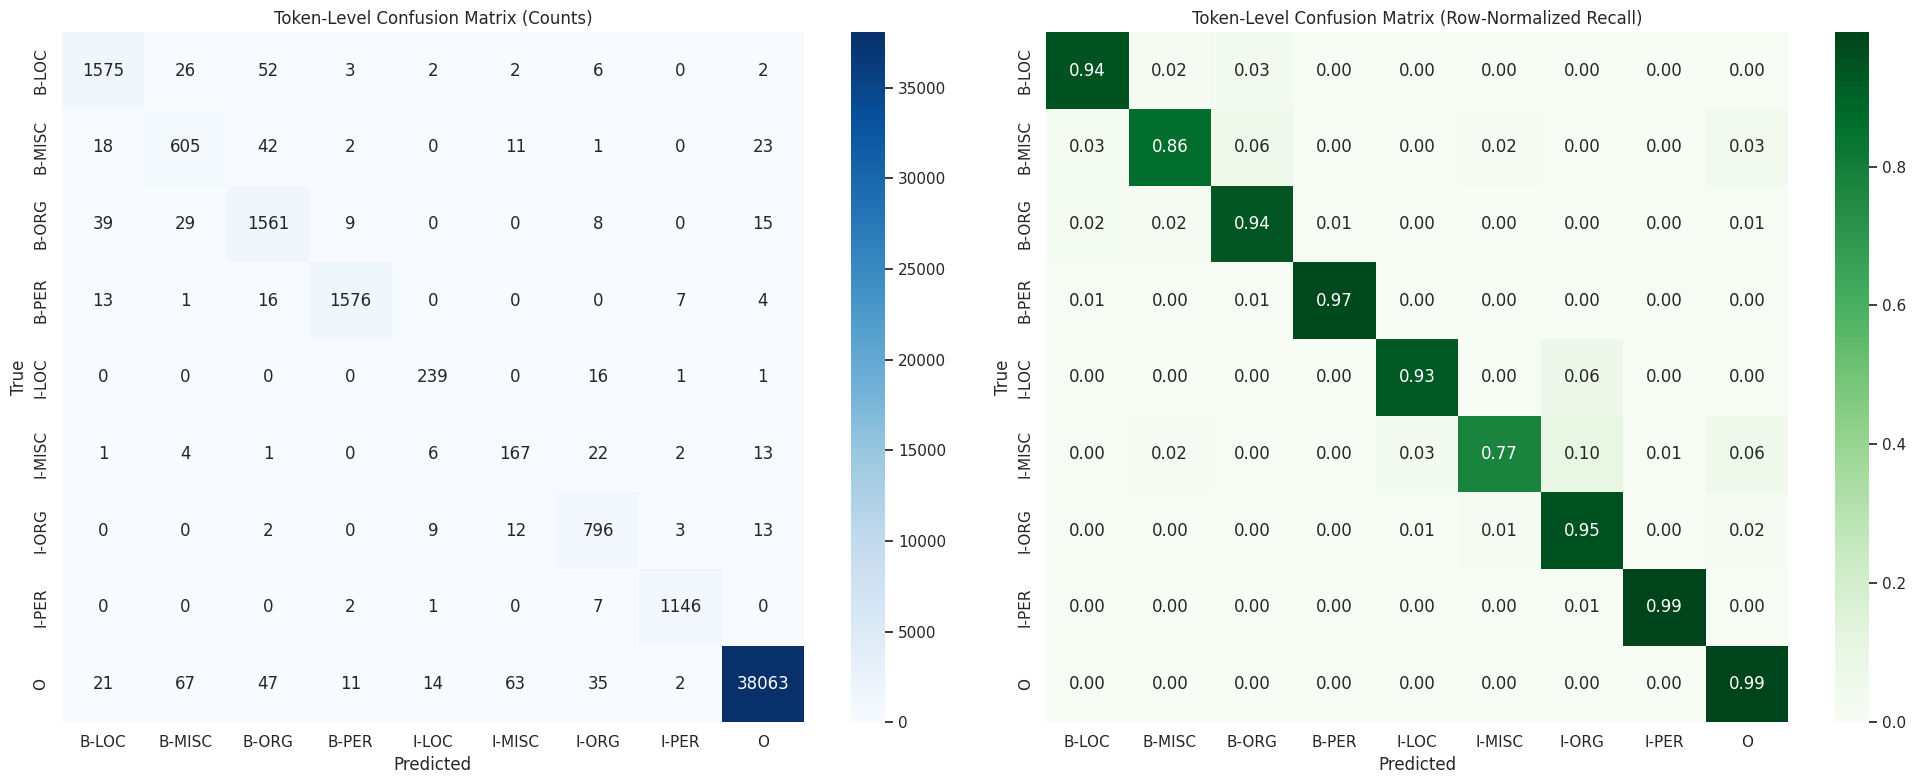


🔝 Top 10 token-level confusions (true → predicted):
   O       → B-MISC  : 67
   O       → I-MISC  : 63
   B-LOC   → B-ORG   : 52
   O       → B-ORG   : 47
   B-MISC  → B-ORG   : 42
   B-ORG   → B-LOC   : 39
   O       → I-ORG   : 35
   B-ORG   → B-MISC  : 29
   B-LOC   → B-MISC  : 26
   B-MISC  → O       : 23


In [24]:
flat_true = [tag for sentence in y_true for tag in sentence]  # تسطيح الوسوم الحقيقية | Flatten gold labels
flat_pred = [tag for sentence in y_pred for tag in sentence]  # تسطيح الوسوم المتوقعة | Flatten predictions
label_order = [id2label[i] for i in range(len(id2label))]  # ترتيب الوسوم حسب الأرقام | Labels ordered by id

cm = confusion_matrix(flat_true, flat_pred, labels=label_order)  # مصفوفة الإرباك بالأعداد | Confusion matrix (counts)
cm_normalized = cm / cm.sum(axis=1, keepdims=True).clip(min=1)  # نفس المصفوفة كنسب لكل صف | Row-normalized version

fig, axes = plt.subplots(1, 2, figsize=(20, 8))  # رسمان متجاوران | Two side-by-side heatmaps
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=label_order, yticklabels=label_order, ax=axes[0])  # خريطة الأعداد | Counts heatmap
axes[0].set_title("Token-Level Confusion Matrix (Counts)")  # عنوان الأعداد | Counts title
sns.heatmap(cm_normalized, annot=True, fmt=".2f", cmap="Greens", xticklabels=label_order, yticklabels=label_order, ax=axes[1])  # خريطة النسب | Normalized heatmap
axes[1].set_title("Token-Level Confusion Matrix (Row-Normalized Recall)")  # عنوان النسب | Normalized title
for axis in axes:  # المرور على الرسمين | Iterate over both axes
    axis.set_xlabel("Predicted")  # محور المتوقع | Predicted axis
    axis.set_ylabel("True")  # محور الحقيقي | True axis
plt.tight_layout()  # ضبط الهوامش | Fix layout
plt.show()  # عرض الرسم | Show the plot

confusions = Counter((t, p) for t, p in zip(flat_true, flat_pred) if t != p)  # عد أزواج الأخطاء | Count error pairs
print("\n🔝 Top 10 token-level confusions (true → predicted):")  # عنوان القائمة | List title
for (true_tag, pred_tag), count in confusions.most_common(10):  # أكثر 10 أخطاء | Ten most frequent errors
    print(f"   {true_tag:<7} → {pred_tag:<7} : {count:,}")  # طباعة الخطأ وعدده | Print the error and its count

# 🧩 Token-Level Confusion Matrix Breakdown
# التحليل التفصيلي لمصفوفة الإرباك

---

### 🎯 Key Observations / الملاحظات الرئيسية
- **EN:**
  - The heavy diagonal shows most tokens are correct; the normalized panel is the one to read because `O` dwarfs everything in the raw counts.
  - Most errors are expected to be **boundary errors** (an entity tag vs `O`, e.g. `B-ORG` ↔ `O`) and **type errors** between `ORG` / `LOC` / `MISC`; confusion between `PER` and the other types should be rare.
  - The top-10 list tells you where to look first when improving the model (more data, augmentation, post-processing).
- **AR:**
  - القطر الكثيف يعني أن معظم التوكنز صحيحة؛ والجزء المعاير (النسب) هو الأهم للقراءة لأن `O` تطغى على كل شيء في الأعداد الخام.
  - الأخطاء المتوقعة غالباً **أخطاء حدود** (وسم كيان مقابل `O` مثل `B-ORG` ↔ `O`) و**أخطاء نوع** بين `ORG` و`LOC` و`MISC`؛ والخلط بين `PER` والأنواع الأخرى يجب أن يكون نادراً.
  - قائمة أعلى 10 أخطاء تدلك على أين تبدأ لتحسين النموذج (بيانات أكثر أو تعزيز أو معالجة لاحقة).

### 🔬 Step 5: Real Error Examples
### الخطوة 5: أمثلة أخطاء حقيقية

- **EN:** Numbers hide patterns; reading actual mistakes shows them. Only the words where gold and prediction differ are printed.
- **AR:** الأرقام تخفي الأنماط وقراءة الأخطاء الفعلية تكشفها. تُطبع فقط الكلمات التي اختلف فيها الأصل عن التنبؤ.

In [25]:
shown = 0  # عدد الأمثلة المعروضة | Number of examples shown
for sentence, gold, pred in zip(test_data, y_true, y_pred):  # المرور على جمل الاختبار | Iterate test sentences
    if gold != pred:  # لو فيه اختلاف | If gold and prediction differ
        wrong = [(w, g, p) for w, g, p in zip(sentence["tokens"], gold, pred) if g != p]  # الكلمات المختلفة فقط | Differing words only
        print("📝", " ".join(sentence["tokens"]))  # الجملة كاملة | The full sentence
        for word, g, p in wrong:  # المرور على الكلمات الخاطئة | Iterate wrong words
            print(f"     {word:<18} gold: {g:<7} pred: {p}")  # عرض الخطأ | Show the error
        shown += 1  # زيادة العداد | Increment counter
    if shown >= 8:  # الاكتفاء بثمانية أمثلة | Stop after eight examples
        break  # إنهاء الحلقة | Exit the loop

📝 SOCCER - JAPAN GET LUCKY WIN , CHINA IN SURPRISE DEFEAT .
     CHINA              gold: B-PER   pred: B-LOC
📝 Cuttitta announced his retirement after the 1995 World Cup , where he took issue with being dropped from the Italy side that faced England in the pool stages .
     1995               gold: B-MISC  pred: O
     World              gold: I-MISC  pred: B-MISC
📝 FREESTYLE SKIING-WORLD CUP MOGUL RESULTS .
     SKIING-WORLD       gold: B-MISC  pred: O
     MOGUL              gold: O       pred: I-MISC
📝 Waqar Younis st Germon b Harris 0
     Germon             gold: B-PER   pred: B-ORG
📝 SOCCER - ENGLISH F.A. CUP SECOND ROUND RESULT .
     F.A.               gold: I-MISC  pred: B-MISC
📝 Result of an English F.A. Challenge
     F.A.               gold: I-MISC  pred: B-ORG
     Challenge          gold: I-MISC  pred: O
📝 RUGBY UNION - LITTLE TO MISS CAMPESE FAREWELL .
     LITTLE             gold: B-PER   pred: O
     CAMPESE            gold: B-PER   pred: I-PER
📝 Barbarians - 15 - Ti

# Phase 6: Packaging & Deployment (Hugging Face Space)
# المرحلة السادسة: التجهيز والنشر (Hugging Face Space)

---

### 🎯 Objective / الهدف العام
- **EN:** Build one self-contained `space_bundle/` folder (model, schema, results, `app.py`, pinned `requirements.txt`, `README.md`), **test the exact `app.py` that will be deployed**, then upload everything in a single commit.
- **AR:** بناء مجلد واحد متكامل `space_bundle/` (النموذج والمخطط والنتائج و`app.py` و`requirements.txt` بإصدارات ثابتة و`README.md`)، و**اختبار نفس ملف `app.py` الذي سيُنشر**، ثم رفع كل شيء في commit واحد.

### 📦 Step 1: Save Deployment Artifacts & Verify Schema Consistency
### الخطوة 1: حفظ ملفات النشر والتحقق من اتساق المخطط

In [26]:
os.makedirs(DEPLOYMENT_DIR, exist_ok=True)  # إنشاء مجلد النشر | Create the deployment folder
best_model.save_pretrained(DEPLOYMENT_DIR)  # حفظ النموذج الأفضل | Save the best model
best_tokenizer.save_pretrained(DEPLOYMENT_DIR)  # حفظ المقطّع | Save the tokenizer
shutil.copy(SCHEMA_PATH, os.path.join(DEPLOYMENT_DIR, "label_schema.json"))  # نسخ مخطط الوسوم | Copy the label schema

with open(os.path.join(DEPLOYMENT_DIR, "label_schema.json"), "r", encoding="utf-8") as f:  # قراءة المخطط المنسوخ | Read the copied schema
    deployed_schema = json.load(f)  # تحميل المحتوى | Load the content
deployed_model = AutoModelForTokenClassification.from_pretrained(DEPLOYMENT_DIR, dtype=torch.float32)  # إعادة تحميل نموذج النشر بدقة fp32 | Reload the deployment model in fp32
assert {int(k): v for k, v in deployed_model.config.id2label.items()} == {int(k): v for k, v in deployed_schema["id2label"].items()}, "Deployed model and schema disagree!"  # تطابق النموذج والمخطط | Model and schema must agree
del deployed_model  # تحرير الذاكرة | Free memory

print("✅ Deployment artifacts saved and verified:")  # تأكيد الحفظ | Confirm the save
for file_name in sorted(os.listdir(DEPLOYMENT_DIR)):  # المرور على الملفات | Iterate over the files
    size_mb = os.path.getsize(os.path.join(DEPLOYMENT_DIR, file_name)) / 1e6  # حجم الملف بالميجا | File size in MB
    print(f"   {file_name:<28} {size_mb:>8.1f} MB")  # عرض الملف وحجمه | Show file and size

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

✅ Deployment artifacts saved and verified:
   config.json                       0.0 MB
   label_schema.json                 0.0 MB
   model.safetensors               735.4 MB
   tokenizer.json                    8.3 MB
   tokenizer_config.json             0.0 MB


### 📋 Step 2: Results Summary (`results.json`)
### الخطوة 2: ملخص النتائج في ملف `results.json`

- **EN:** One machine-readable file with every number the README and portfolio will quote, so the documentation can never drift from the actual run.
- **AR:** ملف واحد مقروء آلياً بكل الأرقام التي سيذكرها الـ README والبورتفوليو، فلا يختلف التوثيق عن التشغيل الفعلي أبداً.

In [27]:
per_type = {  # نتائج كل نوع كيان | Per-entity-type results
    entity_type: {  # نوع الكيان | Entity type
        "precision": round(float(report_dict[entity_type]["precision"]), 4),  # الدقة | Precision
        "recall": round(float(report_dict[entity_type]["recall"]), 4),  # الاستدعاء | Recall
        "f1": round(float(report_dict[entity_type]["f1-score"]), 4),  # F1 | F1
        "support": int(report_dict[entity_type]["support"]),  # عدد الكيانات | Number of gold entities
    }  # نهاية النوع | End of the type
    for entity_type in ["PER", "ORG", "LOC", "MISC"]  # الأنواع الأربعة | The four types
}  # نهاية القاموس | End of dictionary

results = {  # القاموس الشامل للنتائج | Full results dictionary
    "model": MODEL_NAME,  # اسم النموذج | Backbone name
    "dataset": "CoNLL-2003 (English)",  # اسم الداتا | Dataset name
    "best_epoch": best_epoch,  # أفضل إيبوك | Best epoch
    "validation_f1": round(float(best_f1), 4),  # أفضل F1 على التحقق | Best validation F1
    "test": {k: round(float(test_result[k]), 4) for k in ["precision", "recall", "f1", "accuracy"]},  # نتائج الاختبار | Test results
    "test_lowercased": {k: round(float(test_lower_result[k]), 4) for k in ["precision", "recall", "f1", "accuracy"]},  # نتائج الاختبار بحروف صغيرة | Lowercased test results
    "per_type_test": per_type,  # نتائج الأنواع | Per-type results
    "hyperparameters": {"learning_rate": LEARNING_RATE, "batch_size": BATCH_SIZE, "weight_decay": WEIGHT_DECAY, "warmup_ratio": WARMUP_RATIO, "max_epochs": NUM_EPOCHS, "patience": PATIENCE, "lowercase_augmentation": LOWER_PROB, "max_grad_norm": MAX_GRAD_NORM, "seed": SEED},  # إعدادات التدريب | Training settings
    "data": {"train_sentences": len(train_data), "validation_sentences": len(valid_data), "test_sentences": len(test_data), "test_entities": n_gold_entities},  # أرقام الداتا | Dataset sizes
}  # نهاية النتائج | End of results

with open(os.path.join(DEPLOYMENT_DIR, "results.json"), "w", encoding="utf-8") as f:  # فتح ملف النتائج | Open the results file
    json.dump(results, f, indent=4, ensure_ascii=False)  # حفظ النتائج | Save the results
print(json.dumps(results["test"], indent=2), "\nLowercased:", results["test_lowercased"])  # عرض أهم الأرقام | Show headline numbers

{
  "precision": 0.9158,
  "recall": 0.934,
  "f1": 0.9248,
  "accuracy": 0.9848
} 
Lowercased: {'precision': 0.8823, 'recall': 0.8929, 'f1': 0.8875, 'accuracy': 0.9775}


### 🧾 Step 3: Pinned `requirements.txt`
### الخطوة 3: ملف `requirements.txt` بإصدارات ثابتة

- **EN:** `transformers` and `tokenizers` are pinned to the exact versions used here (the model was saved with them). Local build suffixes like `+cu126` are stripped because they do not exist on PyPI. `gradio` is intentionally omitted: the Space installs it from the README `sdk` field. `sentencepiece` is included because DeBERTa-v3 needs it.
- **AR:** تُثبَّت `transformers` و`tokenizers` على نفس الإصدارات المستخدمة هنا (التي حُفظ بها النموذج). وتُحذف لواحق مثل `+cu126` لأنها غير موجودة في PyPI. وتُترك `gradio` عمداً لأن الـ Space يثبّتها من حقل `sdk` في README. وتُضاف `sentencepiece` لأن DeBERTa-v3 تحتاجها.

In [28]:
def pinned(package):  # دالة تثبيت إصدار مكتبة | Pin an installed package version
    return f"{package}=={importlib_metadata.version(package).split('+')[0]}"  # الإصدار بدون لاحقة محلية | Version without local suffix


torch_major_minor = ".".join(importlib_metadata.version("torch").split("+")[0].split(".")[:2])  # أول رقمين من إصدار torch | First two numbers of the torch version
requirements = [pinned("transformers"), pinned("tokenizers"), f"torch>={torch_major_minor}", "sentencepiece>=0.1.99"]  # قائمة المتطلبات | Requirement list

with open(os.path.join(BUNDLE_DIR, "requirements.txt"), "w", encoding="utf-8") as f:  # فتح ملف المتطلبات | Open requirements file
    f.write("\n".join(requirements) + "\n")  # كتابة المتطلبات | Write the requirements
print("📦 requirements.txt:\n" + "\n".join(requirements))  # عرض المحتوى | Show the content

📦 requirements.txt:
transformers==5.22.1
tokenizers==0.23.3
torch>=2.14
sentencepiece>=0.1.99


### 🖥️ Step 4: `app.py` — Single Source of Truth
### الخطوة 4: ملف `app.py` — مصدر واحد للحقيقة

- **EN:** The file is written directly by `%%writefile` (v1 kept a second copy inside a string, which could drift). It tokenizes like CoNLL: punctuation is split from words (`Berlin,` → `Berlin` + `,`), `'s` is separated, and abbreviations like `U.S.` stay whole. Entity offsets come straight from the regex matches, so highlighted spans never include punctuation.
- **AR:** يُكتب الملف مباشرة بـ `%%writefile` (النسخة الأولى كانت تحتفظ بنسخة ثانية داخل نص قد تختلف عن الأصل). ويقطّع بأسلوب CoNLL: الترقيم منفصل عن الكلمات (`Berlin,` ← `Berlin` + `,`) و`'s` منفصلة والاختصارات مثل `U.S.` تبقى كلمة واحدة. ومواضع الكيانات تُؤخذ مباشرة من الـ regex فلا يدخل الترقيم في التلوين أبداً.

In [29]:
%%writefile space_bundle/app.py
import os  # التعامل مع المسارات | Path handling
import re  # التعبيرات النمطية للتقطيع | Regular expressions for tokenization
import gradio as gr  # مكتبة بناء الواجهة | UI library
import torch  # مكتبة بايتورتش | PyTorch library
from transformers import AutoModelForTokenClassification, AutoTokenizer  # تحميل النموذج والمقطّع | Load model and tokenizer

MODEL_DIR = os.path.join(os.path.dirname(os.path.abspath(__file__)), "deployment_artifacts")  # مسار النموذج بجانب الملف | Model path next to this file
MAX_LENGTH = 256  # أقصى طول للتوكنز الفرعية | Max sub-word length

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # تحديد الجهاز | Select device
tokenizer = AutoTokenizer.from_pretrained(MODEL_DIR)  # تحميل المقطّع | Load the tokenizer
model = AutoModelForTokenClassification.from_pretrained(MODEL_DIR, dtype=torch.float32).to(device)  # تحميل النموذج بدقة fp32 | Load the model in fp32
model.eval()  # وضع التقييم | Evaluation mode

ENTITY_COLORS = {"PER": "#ff6b6b", "ORG": "#4dabf7", "LOC": "#51cf66", "MISC": "#fcc419"}  # ألوان الكيانات | Entity colors
TOKEN_PATTERN = re.compile(r"(?:[A-Za-z]\.){2,}|\d+(?:[.,]\d+)+|\w+(?:-\w+)*|['’]s\b|[^\w\s]")  # تقطيع بأسلوب CoNLL | CoNLL-style tokenization


def group_entities(spans, labels):  # دالة تجميع الوسوم إلى كيانات كاملة | Group word labels into complete entities
    entities = []  # قائمة الكيانات | Entity list
    current = None  # الكيان قيد البناء | Entity being built
    for (start, end), label in zip(spans, labels):  # المرور على الكلمات بمواضعها | Iterate words with offsets
        if label == "O":  # لو مش كيان | If not an entity
            current = None  # قفل أي كيان مفتوح | Close any open entity
            continue  # الانتقال للكلمة التالية | Move to next word
        entity_type = label.split("-")[-1]  # نوع الكيان فقط | Entity type only
        if label.startswith("B-") or current is None or current["entity"] != entity_type:  # بداية كيان جديد | A new entity starts
            current = {"entity": entity_type, "start": start, "end": end}  # إنشاء كيان بمواضع حقيقية | New entity with real offsets
            entities.append(current)  # إضافته للقائمة | Add it to the list
        else:  # استمرار نفس الكيان | Same entity continues
            current["end"] = end  # توسيع نهاية الكيان | Extend the entity end
    return entities  # إرجاع الكيانات | Return the entities


def predict_entities(sentence):  # دالة التنبؤ الرئيسية | Main prediction function
    sentence = sentence or ""  # التعامل مع الإدخال الفارغ | Handle empty input
    matches = list(TOKEN_PATTERN.finditer(sentence))  # استخراج الكلمات مع مواضعها | Extract words with offsets
    if not matches:  # لو مفيش كلمات | If there are no words
        return {"text": sentence, "entities": []}  # إرجاع نتيجة فاضية | Return an empty result

    words = [m.group() for m in matches]  # نصوص الكلمات | Word strings
    spans = [(m.start(), m.end()) for m in matches]  # مواضع الكلمات في النص الأصلي | Word offsets in the original text
    inputs = tokenizer(words, is_split_into_words=True, return_tensors="pt", truncation=True, max_length=MAX_LENGTH)  # تقطيع للنموذج | Tokenize for the model
    word_ids = inputs.word_ids(batch_index=0)  # ربط التوكنز الفرعية بالكلمات | Map sub-words to words
    model_inputs = {"input_ids": inputs["input_ids"].to(device), "attention_mask": inputs["attention_mask"].to(device)}  # نقل المدخلات للجهاز | Move inputs to device

    with torch.no_grad():  # بدون جراديانت | No gradients
        logits = model(**model_inputs).logits  # حساب المخرجات | Compute logits
    predictions = torch.argmax(logits, dim=-1)[0].tolist()  # أعلى احتمال لكل توكن | Highest-probability class per token

    word_labels = ["O"] * len(words)  # وسم افتراضي لكل كلمة | Default label per word
    seen_words = set()  # الكلمات التي أخذت وسمها | Words already labeled
    for idx, word_id in enumerate(word_ids):  # المرور على التوكنز الفرعية | Iterate sub-words
        if word_id is not None and word_id not in seen_words:  # أول جزء من كل كلمة فقط | First sub-word per word only
            word_labels[word_id] = model.config.id2label[predictions[idx]]  # تخزين وسم الكلمة | Store the word label
            seen_words.add(word_id)  # تعليم الكلمة كمعالجة | Mark word as processed

    return {"text": sentence, "entities": group_entities(spans, word_labels)}  # الإخراج بصيغة HighlightedText | Output in HighlightedText format


demo = gr.Interface(  # بناء الواجهة | Build the interface
    fn=predict_entities,  # الدالة المنفذة | Function to run
    inputs=gr.Textbox(label="اكتب جملة | Enter a sentence", placeholder="Mohamed Belal works as an AI Engineer at Google in Dubai", lines=2),  # خانة الإدخال | Input box
    outputs=gr.HighlightedText(label="الكيانات المكتشفة | Detected Entities", color_map=ENTITY_COLORS),  # عرض الكيانات الملونة | Colored entity output
    title="🔍 Named Entity Recognition (DeBERTa-v3)",  # العنوان | Title
    description="أدخل جملة بالإنجليزية وشوف الكيانات (أشخاص، مؤسسات، أماكن، متفرقات) ملونة تلقائياً. | Enter an English sentence and see entities (people, organizations, locations, misc) auto-highlighted.",  # الوصف | Description
    examples=[  # أمثلة جاهزة | Ready-made examples
        ["Mohamed Belal works as an AI Engineer at Google in Dubai"],  # مثال 1 | Example 1
        ["Barack Obama visited Paris last week to meet officials from the United Nations"],  # مثال 2 | Example 2
        ["Angela Merkel met Emmanuel Macron in Berlin, Paris, and Rome."],  # مثال بترقيم | Example with punctuation
    ],  # نهاية الأمثلة | End of examples
)  # نهاية الواجهة | End of interface

if __name__ == "__main__":  # نقطة التشغيل | Entry point
    demo.launch()  # تشغيل التطبيق | Launch the app

Writing space_bundle/app.py


### 📝 Step 5: `README.md` (Space Config + Model Card)
### الخطوة 5: ملف `README.md` (إعدادات الـ Space وبطاقة النموذج)

- **EN:** The YAML header configures the Space (`sdk: gradio`, `app_file: app.py`). The body is generated **from `results` above**, so every number matches the real run, including the lowercase-test number and the known limitations.
- **AR:** ترويسة YAML تضبط الـ Space (`sdk: gradio` و`app_file: app.py`). والمحتوى يُولَّد **من `results` أعلاه** فتطابق كل الأرقام التشغيل الفعلي، ومنها رقم الاختبار بالحروف الصغيرة والقيود المعروفة.

In [30]:
test_scores = results["test"]  # نتائج الاختبار | Test scores
lower_scores = results["test_lowercased"]  # نتائج الاختبار بحروف صغيرة | Lowercased scores

readme_lines = [  # أسطر الـ README | README lines
    "---",  # بداية الترويسة | YAML start
    "title: Named Entity Recognition (DeBERTa-v3)",  # عنوان الـ Space | Space title
    "emoji: 🔍",  # الإيموجي | Emoji
    "colorFrom: blue",  # لون البداية | Gradient start
    "colorTo: green",  # لون النهاية | Gradient end
    "sdk: gradio",  # نوع الـ SDK | SDK type
    "app_file: app.py",  # ملف التطبيق | App file
    "pinned: false",  # عدم التثبيت | Not pinned
    "license: mit",  # الرخصة | License
    "---",  # نهاية الترويسة | YAML end
    "",  # سطر فارغ | Blank line
    "# Named Entity Recognition — DeBERTa-v3-base on CoNLL-2003",  # العنوان الرئيسي | Main heading
    "",  # سطر فارغ | Blank line
    f"Fine-tuned `{MODEL_NAME}` for English NER (PER, ORG, LOC, MISC) on CoNLL-2003.",  # وصف النموذج | Model description
    "",  # سطر فارغ | Blank line
    "## Results (entity-level, seqeval)",  # عنوان النتائج | Results heading
    "",  # سطر فارغ | Blank line
    f"- Test F1: **{test_scores['f1'] * 100:.2f}** (precision {test_scores['precision'] * 100:.2f}, recall {test_scores['recall'] * 100:.2f})",  # نتيجة الاختبار | Test result
    f"- Validation F1 (official dev set, best epoch {results['best_epoch']}): **{results['validation_f1'] * 100:.2f}**",  # نتيجة التحقق | Validation result
    f"- Test F1 with fully lowercased input: **{lower_scores['f1'] * 100:.2f}**",  # نتيجة الحروف الصغيرة | Lowercased result
]  # نهاية الجزء الأول | End of first part

for entity_type, scores in results["per_type_test"].items():  # المرور على الأنواع | Iterate over types
    readme_lines.append(f"- {entity_type}: F1 {scores['f1'] * 100:.2f} (support {scores['support']})")  # سطر لكل نوع | One line per type

readme_lines += [  # بقية الأسطر | Remaining lines
    "",  # سطر فارغ | Blank line
    "## Training setup",  # عنوان الإعدادات | Setup heading
    "",  # سطر فارغ | Blank line
    f"- Official CoNLL-2003 train/validation/test splits, `-DOCSTART-` markers removed ({len(train_data):,} / {len(valid_data):,} / {len(test_data):,} sentences)",  # أرقام الداتا | Data sizes
    "- First-sub-word label alignment; entity-level evaluation with seqeval",  # طريقة التقييم | Evaluation method
    f"- AdamW, lr {LEARNING_RATE}, weight decay {WEIGHT_DECAY}, linear warmup ({int(WARMUP_RATIO * 100)}%) + decay, gradient clipping {MAX_GRAD_NORM}, seed {SEED}",  # إعدادات التحسين | Optimization settings
    f"- Lowercase augmentation on {int(LOWER_PROB * 100)}% of training sentences; best checkpoint chosen by validation F1 with early stopping",  # التعزيز والاختيار | Augmentation and selection
    "",  # سطر فارغ | Blank line
    "## Limitations",  # عنوان القيود | Limitations heading
    "",  # سطر فارغ | Blank line
    "- English only; trained on 1990s Reuters newswire, so modern or domain-specific text (tech, social media) may degrade.",  # قيد اللغة والمجال | Language and domain limit
    "- Performance depends on capitalization; see the lowercased-input score above.",  # قيد الحروف | Casing limit
    "- MISC is a heterogeneous category and the weakest type; ORG/LOC ambiguity (e.g. city names used for teams) is the most common confusion.",  # قيود الأنواع | Type limits
    "- Inputs longer than 256 sub-word tokens are truncated.",  # قيد الطول | Length limit
]  # نهاية الأسطر | End of lines

with open(os.path.join(BUNDLE_DIR, "README.md"), "w", encoding="utf-8") as f:  # فتح ملف README | Open the README file
    f.write("\n".join(readme_lines) + "\n")  # كتابة المحتوى | Write the content
print("\n".join(readme_lines))  # عرض المحتوى | Show the content

---
title: Named Entity Recognition (DeBERTa-v3)
emoji: 🔍
colorFrom: blue
colorTo: green
sdk: gradio
app_file: app.py
pinned: false
license: mit
---

# Named Entity Recognition — DeBERTa-v3-base on CoNLL-2003

Fine-tuned `microsoft/deberta-v3-base` for English NER (PER, ORG, LOC, MISC) on CoNLL-2003.

## Results (entity-level, seqeval)

- Test F1: **92.48** (precision 91.58, recall 93.40)
- Validation F1 (official dev set, best epoch 5): **96.21**
- Test F1 with fully lowercased input: **88.75**
- PER: F1 97.58 (support 1617)
- ORG: F1 91.01 (support 1661)
- LOC: F1 93.90 (support 1668)
- MISC: F1 81.30 (support 702)

## Training setup

- Official CoNLL-2003 train/validation/test splits, `-DOCSTART-` markers removed (14,041 / 3,250 / 3,453 sentences)
- First-sub-word label alignment; entity-level evaluation with seqeval
- AdamW, lr 2e-05, weight decay 0.01, linear warmup (10%) + decay, gradient clipping 1.0, seed 42
- Lowercase augmentation on 20% of training sentences; best checkpoint

### 🧪 Step 6: End-to-End Test of the Exact `app.py`
### الخطوة 6: اختبار شامل لنفس ملف `app.py` المنشور

- **EN:** Import the written `app.py` and run the sentences that exposed v1's problems. Hard assertions cover only deterministic behaviour (no entity may start or end with punctuation); model-quality checks are printed as ✅/⚠️ because no model is perfect.
- **AR:** استيراد ملف `app.py` المكتوب وتشغيل الجمل التي كشفت مشاكل النسخة الأولى. التأكيدات الصارمة تغطي السلوك الحتمي فقط (لا يبدأ ولا ينتهي أي كيان بعلامة ترقيم)، أما جودة النموذج فتُطبع كـ ✅/⚠️ لأن لا نموذج مثالي.

In [31]:
!pip install -q gradio

In [32]:
import sys  # التحكم في مسارات الاستيراد | Control import paths
import importlib  # استيراد وحدة بالاسم | Import a module by name

if BUNDLE_DIR not in sys.path:  # لو المسار غير مضاف | If the path is not registered
    sys.path.insert(0, BUNDLE_DIR)  # إضافة مجلد الحزمة | Add the bundle folder
if "app" in sys.modules:  # لو الوحدة محمّلة من قبل | If the module was already imported
    del sys.modules["app"]  # حذفها لإعادة التحميل | Drop it to force a fresh import
app = importlib.import_module("app")  # استيراد app.py الحقيقي | Import the real app.py

test_cases = [  # جمل الاختبار مع الكيانات المتوقعة | Test sentences with expected entities
    ("Barack Obama visited Paris last week to meet officials from the United Nations", {("Barack Obama", "PER"), ("Paris", "LOC"), ("United Nations", "ORG")}),  # اختبار أساسي | Basic test
    ("Angela Merkel met Emmanuel Macron in Berlin, Paris, and Rome.", {("Angela Merkel", "PER"), ("Emmanuel Macron", "PER"), ("Berlin", "LOC"), ("Paris", "LOC"), ("Rome", "LOC")}),  # ترقيم لاصق | Attached punctuation
    ("Bank of America opened an office in New York City.", {("Bank of America", "ORG"), ("New York City", "LOC")}),  # كيانات متعددة الكلمات | Multi-word entities
    ("The German team beat the Brazilian side at the Olympic Games.", {("German", "MISC"), ("Brazilian", "MISC"), ("Olympic Games", "MISC")}),  # جنسيات وأحداث | Nationalities and events
    ("elon musk founded spacex in california", {("elon musk", "PER"), ("spacex", "ORG"), ("california", "LOC")}),  # حروف صغيرة | Lowercase input
    ("Washington signed the deal with Beijing, while Washington Post reported it.", None),  # لبس ORG/LOC بدون توقع ثابت | ORG/LOC ambiguity, no fixed expectation
]  # نهاية الجمل | End of test sentences

PUNCTUATION = ",.;:!?\"'()[]"  # علامات الترقيم الممنوعة على حدود الكيان | Punctuation forbidden at entity edges
for sentence, expected in test_cases:  # المرور على الجمل | Iterate over sentences
    output = app.predict_entities(sentence)  # تشغيل دالة التطبيق | Run the app function
    found = {(sentence[e["start"]:e["end"]], e["entity"]) for e in output["entities"]}  # الكيانات المستخرجة | Extracted entities
    for text, _ in found:  # فحص حدود كل كيان | Check each entity's edges
        assert text and text[0] not in PUNCTUATION and text[-1] not in PUNCTUATION, f"Punctuation leaked into entity: {text!r}"  # الترقيم ممنوع | No punctuation allowed
    status = "ℹ️" if expected is None else ("✅" if found == expected else "⚠️")  # حالة الجودة | Quality status
    print(f"{status} {sentence}\n     → {sorted(found)}")  # عرض النتيجة | Show the result
    if expected is not None and found != expected:  # لو فيه اختلاف عن المتوقع | If it differs from expectation
        print(f"     expected: {sorted(expected)}")  # عرض المتوقع | Show the expectation

assert app.predict_entities("")["entities"] == [], "Empty input must return no entities"  # الإدخال الفارغ آمن | Empty input is safe
print("\n✅ Deterministic checks passed (no punctuation leakage, empty input handled)")  # تأكيد النجاح | Confirm success

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

✅ Barack Obama visited Paris last week to meet officials from the United Nations
     → [('Barack Obama', 'PER'), ('Paris', 'LOC'), ('United Nations', 'ORG')]
✅ Angela Merkel met Emmanuel Macron in Berlin, Paris, and Rome.
     → [('Angela Merkel', 'PER'), ('Berlin', 'LOC'), ('Emmanuel Macron', 'PER'), ('Paris', 'LOC'), ('Rome', 'LOC')]
✅ Bank of America opened an office in New York City.
     → [('Bank of America', 'ORG'), ('New York City', 'LOC')]
✅ The German team beat the Brazilian side at the Olympic Games.
     → [('Brazilian', 'MISC'), ('German', 'MISC'), ('Olympic Games', 'MISC')]
✅ elon musk founded spacex in california
     → [('california', 'LOC'), ('elon musk', 'PER'), ('spacex', 'ORG')]
ℹ️ Washington signed the deal with Beijing, while Washington Post reported it.
     → [('Beijing', 'LOC'), ('Washington', 'LOC'), ('Washington Post', 'ORG')]

✅ Deterministic checks passed (no punctuation leakage, empty input handled)


# 📊 Output Analysis: End-to-End Test
# تحليل المخرجات: الاختبار الشامل

---

### 🎯 How to Read the Results / كيف تقرأ النتائج
- **EN:**
  - The hard assertions guarantee the v1 punctuation bug (`Berlin,` highlighted with its comma) cannot return.
  - ⚠️ lines are *model* disagreements with my expectations, not code failures: inspect them, and if they are genuine errors add them to the README limitations rather than hiding them.
  - The lowercase sentence is the measurable effect of the augmentation; compare it with the v1 Space, which returned no entities at all.
- **AR:**
  - التأكيدات الصارمة تضمن ألا يعود خطأ الترقيم في النسخة الأولى (`Berlin,` بفاصلتها داخل التلوين).
  - أسطر ⚠️ هي اختلافات *النموذج* عن توقعاتي وليست أعطال كود: افحصها، ولو كانت أخطاء حقيقية فأضفها لقيود README بدل إخفائها.
  - جملة الحروف الصغيرة هي الأثر القابل للقياس للتعزيز؛ قارنها بنسخة الـ Space الأولى التي لم تُرجع أي كيان.

### 🚀 Step 7: Upload to Hugging Face Spaces (Single Commit)
### الخطوة 7: الرفع إلى Hugging Face Spaces (commit واحد)

- **EN:** Uploads the whole `space_bundle/` folder at once so the Space rebuilds a single time. The token is read from Colab Secrets (`HF_TOKEN`) and never written in the notebook.
- **AR:** يرفع مجلد `space_bundle/` بالكامل مرة واحدة فيُعاد بناء الـ Space مرة واحدة فقط. ويُقرأ التوكن من Colab Secrets (`HF_TOKEN`) ولا يُكتب في الـ notebook أبداً.

In [34]:
import os  # التعامل مع المسارات | Path handling
import sys  # مسارات الاستيراد | Import paths
import importlib  # استيراد الوحدات بالاسم | Import modules by name

MODEL_REPO_ID = "MohamedBelal-AI/deberta-v3-base-conll2003-ner"  # مستودع الموديل على الهاب | Model repository on the Hub
BUNDLE_DIR = "./space_bundle"  # مجلد ملفات التطبيق | App files folder

os.environ["NER_MODEL_ID"] = MODEL_REPO_ID  # توجيه التطبيق لموديل الهاب | Point the app at the Hub model
if BUNDLE_DIR not in sys.path:  # لو المسار غير مضاف | If the path is not registered
    sys.path.insert(0, BUNDLE_DIR)  # إضافة مجلد التطبيق | Add the app folder
sys.modules.pop("app", None)  # حذف أي نسخة محملة سابقاً | Drop any previously imported copy
hub_app = importlib.import_module("app")  # تحميل التطبيق والموديل من الهاب | Load the app and the model from the Hub

probe_sentence = "Angela Merkel met Emmanuel Macron in Berlin, Paris, and Rome."  # جملة الفحص | Probe sentence
probe = hub_app.predict_entities(probe_sentence)  # تشغيل التنبؤ | Run the prediction
print([(probe_sentence[e["start"]:e["end"]], e["entity"]) for e in probe["entities"]])  # عرض الكيانات | Show the entities

hub_app.demo.launch(share=True)  # تشغيل الواجهة بلينك عام مؤقت | Launch the UI with a temporary public link

config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/645 [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/8.34M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  735MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[('Angela Merkel', 'PER'), ('Emmanuel Macron', 'PER'), ('Berlin', 'LOC'), ('Paris', 'LOC'), ('Rome', 'LOC')]
Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://81b8f1ed5797b08163.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


# 🏁 Final Summary
# الملخص النهائي

---

In [35]:
print("=" * 64)  # فاصل | Separator
print("🏁 FINAL RESULTS SUMMARY")  # العنوان | Title
print("=" * 64)  # فاصل | Separator
print(f"Model            : {results['model']}")  # النموذج | Model
print(f"Dataset          : {results['dataset']} ({results['data']['train_sentences']:,} / {results['data']['validation_sentences']:,} / {results['data']['test_sentences']:,} sentences)")  # الداتا | Dataset
print(f"Best epoch       : {results['best_epoch']}")  # أفضل إيبوك | Best epoch
print(f"Validation F1    : {results['validation_f1']:.4f}")  # F1 التحقق | Validation F1
print(f"Test F1          : {results['test']['f1']:.4f}  (P {results['test']['precision']:.4f} | R {results['test']['recall']:.4f})")  # F1 الاختبار | Test F1
print(f"Test F1 lowercase: {results['test_lowercased']['f1']:.4f}")  # F1 بحروف صغيرة | Lowercased F1
for entity_type, scores in results["per_type_test"].items():  # المرور على الأنواع | Iterate over types
    print(f"   {entity_type:<5} F1 {scores['f1']:.4f}  (support {scores['support']})")  # نتيجة كل نوع | Per-type score
print("=" * 64)  # فاصل | Separator

🏁 FINAL RESULTS SUMMARY
Model            : microsoft/deberta-v3-base
Dataset          : CoNLL-2003 (English) (14,041 / 3,250 / 3,453 sentences)
Best epoch       : 5
Validation F1    : 0.9621
Test F1          : 0.9248  (P 0.9158 | R 0.9340)
Test F1 lowercase: 0.8875
   PER   F1 0.9758  (support 1617)
   ORG   F1 0.9101  (support 1661)
   LOC   F1 0.9390  (support 1668)
   MISC  F1 0.8130  (support 702)
